# Visualization (Only predicted data)

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import os
import pandas as pd
import numpy as np 
import re
from matplotlib.patches import Ellipse


In [2]:
belief_col = 'Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol'

In [3]:
# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

In [4]:
base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{belief_col}"

In [5]:
# Define label mappings for demographic groups
label_mappings = {
    'sex_idx': {
        1: "Male",
        2: "Female"
    },
    'age_idx': {
        1: "18-24",
        2: "25-34",
        3: "35-44",
        4: "45-54",
        5: "55-64",
        6: "65+"
    },
    'eth_idx': {
        1: "White",
        2: "Black",
        3: "Hispanic",
        4: "Asian",
        5: "American Indian",
        6: "Multiracial"
    },
    'income_idx': {
        1: "<$25k",
        2: "$25k-$50k",
        3: "$50k-$75k",
        4: "$75k-$100k",
        5: ">$100k"
    },
    'vote_idx': {
        1: "Did not vote",
        2: "Republican",
        3: "Democrat",
        4: "Libertarian",
        5: "Green",
        6: "Other"
    },
    'state_idx': {
        1: "AL", 2: "AK", 3: "AZ", 4: "AR", 5: "CA", 6: "CO", 7: "CT", 8: "DE", 9: "FL", 10: "GA",
        11: "HI", 12: "ID", 13: "IL", 14: "IN", 15: "IA", 16: "KS", 17: "KY", 18: "LA", 19: "ME", 20: "MD",
        21: "MA", 22: "MI", 23: "MN", 24: "MS", 25: "MO", 26: "MT", 27: "NE", 28: "NV", 29: "NH", 30: "NJ",
        31: "NM", 32: "NY", 33: "NC", 34: "ND", 35: "OH", 36: "OK", 37: "OR", 38: "PA", 39: "RI", 40: "SC",
        41: "SD", 42: "TN", 43: "TX", 44: "UT", 45: "VT", 46: "VA", 47: "WA", 48: "WV", 49: "WI", 50: "WY"
    },
    'education_idx': {
        1: "Up and including high school",
        2: "College or university level"
    }
}

def apply_labels(data, group_col):
    """
    Apply labels to group column values.
    
    Parameters:
    - data: DataFrame with group column
    - group_col: Name of the group column
    
    Returns:
    - DataFrame with renamed group values
    """
    data = data.copy()
    if group_col in label_mappings:
        data[group_col] = data[group_col].map(label_mappings[group_col]).fillna(data[group_col])
    return data

print("Label mappings loaded successfully!")

Label mappings loaded successfully!


In [6]:
# Load consolidated time series data for each demographic group
def load_group_timeseries(base_dir, group_name):
    """Load time series predictions for a demographic group."""
    file_path = f"{base_dir}/group_{group_name}_category_probs_timeseries.csv"
    if os.path.exists(file_path):
        return pd.read_csv(file_path)
    else:
        print(f"Warning: {file_path} not found")
        return None

# Load all available group time series
groups_to_load = ['sex', 'age', 'eth', 'income', 'vote', 'state','education']
group_data = {}

for gname in groups_to_load:
    data = load_group_timeseries(base_dir, gname)
    if data is not None:
        group_data[gname] = data
        print(f"Loaded {gname}: {len(data)} rows, {data['time_window_start'].nunique()} time windows")

print(f"\nAvailable groups: {list(group_data.keys())}")

Loaded sex: 260 rows, 26 time windows
Loaded age: 780 rows, 26 time windows
Loaded eth: 780 rows, 26 time windows
Loaded income: 650 rows, 26 time windows
Loaded vote: 780 rows, 26 time windows
Loaded state: 6630 rows, 26 time windows
Loaded education: 260 rows, 26 time windows

Available groups: ['sex', 'age', 'eth', 'income', 'vote', 'state', 'education']


In [7]:
group_data

{'sex':      sex_idx  prob_mean  category          time_window_start
 0          1   0.020678         1  2023-11-05 00:00:00+00:00
 1          2   0.018253         1  2023-11-05 00:00:00+00:00
 2          1   0.006865         2  2023-11-05 00:00:00+00:00
 3          2   0.006166         2  2023-11-05 00:00:00+00:00
 4          1   0.044140         3  2023-11-05 00:00:00+00:00
 ..       ...        ...       ...                        ...
 255        2   0.063763         3  2024-10-20 00:00:00+00:00
 256        1   0.029623         4  2024-10-20 00:00:00+00:00
 257        2   0.025887         4  2024-10-20 00:00:00+00:00
 258        1   0.801223         5  2024-10-20 00:00:00+00:00
 259        2   0.835403         5  2024-10-20 00:00:00+00:00
 
 [260 rows x 4 columns],
 'age':      age_idx  prob_mean  category          time_window_start
 0          1   0.020922         1  2023-11-05 00:00:00+00:00
 1          2   0.011591         1  2023-11-05 00:00:00+00:00
 2          3   0.009670     

In [8]:
group_data['age']

,age_idx,prob_mean,category,time_window_start
0,1,0.020922,1,2023-11-05 00:00:00+00:00
1,2,0.011591,1,2023-11-05 00:00:00+00:00
2,3,0.009670,1,2023-11-05 00:00:00+00:00
3,4,0.014341,1,2023-11-05 00:00:00+00:00
4,5,0.018781,1,2023-11-05 00:00:00+00:00
...,...,...,...,...
775,2,0.882968,5,2024-10-20 00:00:00+00:00
776,3,0.901429,5,2024-10-20 00:00:00+00:00
777,4,0.883862,5,2024-10-20 00:00:00+00:00
778,5,0.828860,5,2024-10-20 00:00:00+00:00


In [9]:
# Function: Plot category probabilities over time for specific groups
def plot_category_timeseries(data, group_col, group_values=None, figsize=(14, 8), 
                             title_prefix="", ncols=2, save_path=None):
    """
    Plot category probability time series for selected group values.
    
    Parameters:
    - data: DataFrame with columns [group_col, category, prob_mean, time_window_start]
    - group_col: Name of the grouping column
    - group_values: List of specific group values to plot (None = plot all)
    - figsize: Figure size
    - title_prefix: Prefix for plot title
    - ncols: Number of columns in subplot grid
    - save_path: Path to save the plot (e.g., 'plots/category_timeseries.png')
    """
    if data is None or len(data) == 0:
        print(f"No data available for {group_col}")
        return
    
    # Filter to specific group values if provided
    if group_values is not None:
        data = data[data[group_col].isin(group_values)].copy()
    
    # Apply labels if available
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups found in {group_col}")
        return
    
    # Convert time windows to datetime for better plotting
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    categories = sorted(data['category'].unique())
    colors = sns.color_palette("husl", len(categories))
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_subset = data[data[group_col] == group_val]
        
        for cat_idx, cat in enumerate(categories):
            cat_data = group_subset[group_subset['category'] == cat].sort_values('time_dt')
            ax.plot(cat_data['time_dt'], cat_data['prob_mean'], 
                   marker='o', label=f'Category {cat}', color=colors[cat_idx], linewidth=2)
        
        ax.set_title(f"{title_prefix}{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Probability')
        ax.legend(loc='best', fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylim([0, 1])
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_category_timeseries()")


Function loaded: plot_category_timeseries()


In [10]:
# Weighted national stacked area from cell-level predictions (aggregate per time window)
time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
time_windows = sorted([
    d.replace(f"{belief_col}_", "").replace("_stan_output", "")
    for d in time_window_dirs
])

weight_col = 'N_star.median'
prob_cols = None
records = []
windows_loaded = 0

for window in time_windows:
    pred_file = f"{base_dir}/{belief_col}_{window}_stan_output/cell_level_predictions.csv"
    if not os.path.exists(pred_file):
        continue

    # Discover probability columns once from header
    if prob_cols is None:
        header_cols = pd.read_csv(pred_file, nrows=0).columns.tolist()
        prob_cols = [
            c for c in header_cols
            if c.startswith(f"{belief_col}_prob_cat_mean_")
        ]
        if weight_col not in header_cols:
            raise ValueError(f"Required weight column '{weight_col}' not found in cell_level_predictions.csv")
        if len(prob_cols) == 0:
            raise ValueError("No category mean probability columns found.")
        prob_cols = sorted(prob_cols, key=lambda x: int(x.split('_')[-1]))

    # Read only needed columns for speed/memory
    usecols = [weight_col] + prob_cols
    preds = pd.read_csv(pred_file, usecols=usecols)

    w = pd.to_numeric(preds[weight_col], errors='coerce')
    w_positive = w > 0

    # Aggregate weighted mean for each category within this time window
    for col in prob_cols:
        p = pd.to_numeric(preds[col], errors='coerce')
        valid = w_positive & p.notna() & w.notna()
        if valid.any():
            category = int(col.split('_')[-1])
            national_prob = np.average(p[valid], weights=w[valid])
            records.append({
                'time_window_start': window,
                'category': category,
                'national_prob': national_prob
            })

    windows_loaded += 1

if len(records) == 0:
    raise ValueError("No valid weighted national predictions were produced.")

national_weighted = pd.DataFrame(records)
national_weighted['time_dt'] = pd.to_datetime(national_weighted['time_window_start'])

national_pivot_weighted = (
    national_weighted
    .pivot(index='time_dt', columns='category', values='national_prob')
    .sort_index()
    .fillna(0)
 )

# Optional safeguard: normalize each row to sum to 1
row_sums = national_pivot_weighted.sum(axis=1).replace(0, np.nan)
national_pivot_weighted = national_pivot_weighted.div(row_sums, axis=0).fillna(0)

# Plot at the end
fig, ax = plt.subplots(figsize=(14, 7))
colors = sns.color_palette("RdYlGn", n_colors=national_pivot_weighted.shape[1])
ax.stackplot(
    national_pivot_weighted.index,
    *[national_pivot_weighted[c].values for c in national_pivot_weighted.columns],
    labels=[f"Cat {c}" for c in national_pivot_weighted.columns],
    colors=colors,
    alpha=0.85
 )
ax.set_title("National-Level Predicted Category Composition Over Time (Population Weighted)", fontsize=13, fontweight='bold')
ax.set_xlabel('Time Window')
ax.set_ylabel('Probability')
ax.set_ylim(0, 1)
ax.grid(True, axis='y', alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Save
os.makedirs(f"{base_dir}/visualizations", exist_ok=True)
national_weighted_plot_path = f"{base_dir}/visualizations/national_stacked_area_weighted_cell_level.png"
plt.savefig(national_weighted_plot_path, dpi=300, bbox_inches='tight')
print(f"Saved: {national_weighted_plot_path}")
print(f"Loaded windows: {windows_loaded} | Aggregated points: {len(records):,}")
plt.show()

# Keep in memory for reuse
national_pivot = national_pivot_weighted.copy()
national_pivot.head()

ValueError: Required weight column 'N_star.median' not found in cell_level_predictions.csv

In [11]:
df = pd.read_pickle('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/preprocessed_cleaned_all_result.pkl')

In [13]:
predictor_cols = [
    "Demo_sex_Symbol",
    "Demo_age_Symbol",
    "Demo_ethnicity_Symbol",
    "Demo_income_Symbol",
    "Demo_education_Symbol",
    "Demo_past_vote_Symbol",
    "state_cleaned"
]
df = df.dropna(subset=[belief_col] + predictor_cols)

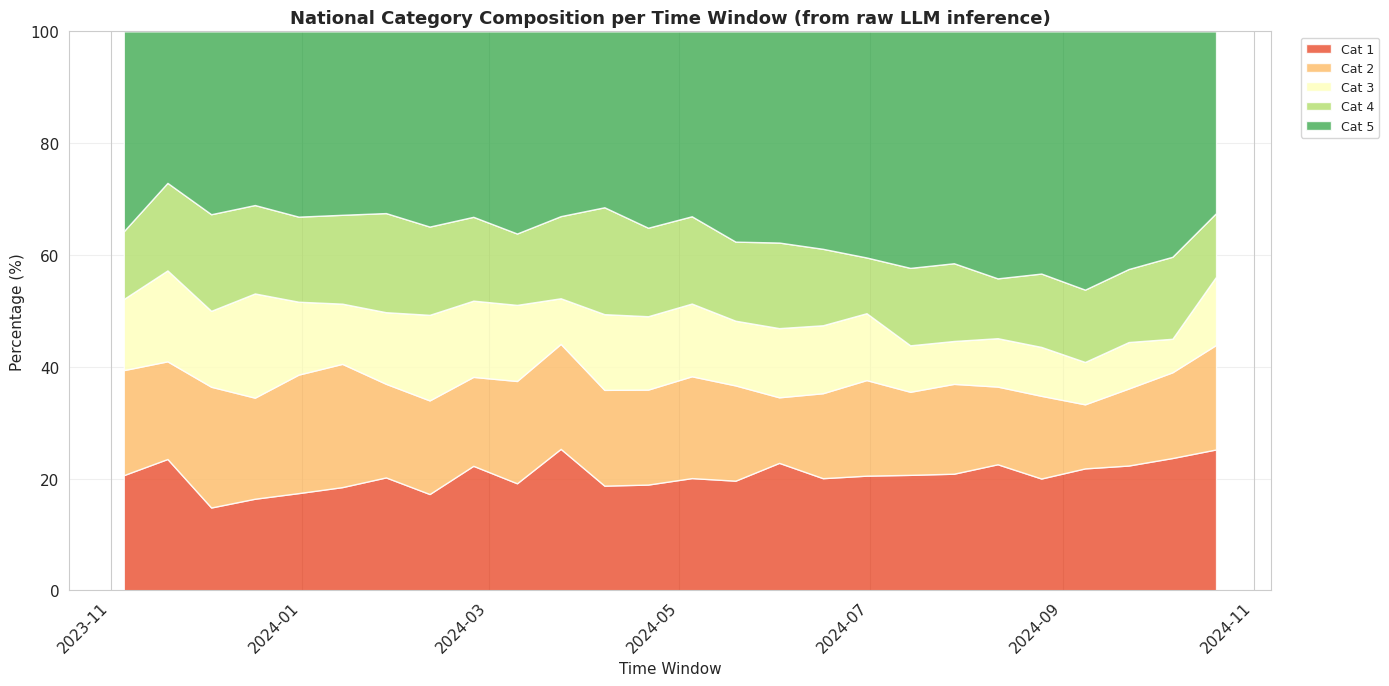

Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_num,1,2,3,4,5
time_window_start,,,,,
2023-11-05 00:00:00+00:00,20.606061,18.787879,12.727273,12.121212,35.757576
2023-11-19 00:00:00+00:00,23.493976,17.469880,16.265060,15.662651,27.108434
2023-12-03 00:00:00+00:00,14.814815,21.604938,13.580247,17.283951,32.716049
2023-12-17 00:00:00+00:00,16.384181,18.079096,18.644068,15.819209,31.073446
2023-12-31 00:00:00+00:00,17.391304,21.195652,13.043478,15.217391,33.152174


In [14]:
# National stacked area plot per time window from df (using belief_col + "num")
choice_col = f"{belief_col}_num"

if choice_col not in df.columns:
    raise ValueError(f"Column not found: {choice_col}")

plot_df = df.copy()

# Use existing time-window assignment if available; otherwise derive from date + model windows
if 'time_window_start' not in plot_df.columns:
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([
        d.replace(f"{belief_col}_", "").replace("_stan_output", "")
        for d in time_window_dirs
    ])

    # Keep only parseable time-window strings
    time_windows_clean = []
    for tw in time_windows:
        tw_str = str(tw)
        tw_str = re.sub(r'_(stan|vglmer)_output$', '', tw_str)
        if not pd.isna(pd.to_datetime(tw_str, errors='coerce')):
            time_windows_clean.append(tw_str)
    time_windows_clean = sorted(set(time_windows_clean))

    # Try to find a usable date column
    date_candidates = ['interview_date', 'date', 'dateintv', 'created_at', 'timestamp']
    date_col = next((c for c in date_candidates if c in plot_df.columns), None)
    if date_col is None:
        raise ValueError("No 'time_window_start' column found, and no usable date column to derive it.")

    date_series = plot_df[date_col].copy()

    # Handle GSS-style MMDD dateintv when needed
    if date_col == 'dateintv':
        def _convert_mmdd_to_datetime(x):
            if pd.isna(x):
                return pd.NaT
            s = str(x)
            s = re.sub(r"\D", "", s)
            if s == "":
                return pd.NaT
            s = s.zfill(4)
            month, day = int(s[:2]), int(s[2:])
            try:
                return pd.to_datetime(f"2024-{month:02d}-{day:02d}")
            except Exception:
                return pd.NaT
        date_series = date_series.apply(_convert_mmdd_to_datetime)
    else:
        date_series = pd.to_datetime(date_series, errors='coerce')

    window_dt = [pd.to_datetime(tw) for tw in time_windows_clean]

    def _assign_time_window(date_val):
        if pd.isna(date_val):
            return None
        for i, start in enumerate(window_dt):
            if i < len(window_dt) - 1:
                end = window_dt[i + 1]
                if start <= date_val < end:
                    return time_windows_clean[i]
            else:
                if date_val >= start:
                    return time_windows_clean[i]
        return None

    plot_df['time_window_start'] = date_series.apply(_assign_time_window)

# Keep valid rows only
plot_df = plot_df.dropna(subset=['time_window_start', choice_col]).copy()
plot_df[choice_col] = pd.to_numeric(plot_df[choice_col], errors='coerce')
plot_df = plot_df.dropna(subset=[choice_col]).copy()
plot_df[choice_col] = plot_df[choice_col].astype(int)

# Count and convert to within-window percentage
counts = (
    plot_df
    .groupby(['time_window_start', choice_col])
    .size()
    .reset_index(name='count')
)

totals = counts.groupby('time_window_start')['count'].transform('sum')
counts['percentage'] = np.where(totals > 0, counts['count'] / totals * 100, np.nan)

# Pivot for stackplot
stack_data = (
    counts.pivot(index='time_window_start', columns=choice_col, values='percentage')
    .fillna(0)
    .sort_index(key=lambda s: pd.to_datetime(s, errors='coerce'))
)

# Keep categories in numeric order
stack_data = stack_data.reindex(sorted(stack_data.columns), axis=1)

fig, ax = plt.subplots(figsize=(14, 7))
colors = sns.color_palette("RdYlGn", n_colors=len(stack_data.columns))
ax.stackplot(
    pd.to_datetime(stack_data.index, errors='coerce'),
    *[stack_data[c].values for c in stack_data.columns],
    labels=[f"Cat {c}" for c in stack_data.columns],
    colors=colors,
    alpha=0.85
)

ax.set_title("National Category Composition per Time Window (from raw LLM inference)", fontsize=13, fontweight='bold')
ax.set_xlabel('Time Window')
ax.set_ylabel('Percentage (%)')
ax.set_ylim(0, 100)
ax.grid(True, axis='y', alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

stack_data.head()

In [15]:
preds

NameError: name 'preds' is not defined

In [11]:
# Plot expected value time series with 95% credible intervals for a demographic group
def plot_expected_value_trends(base_dir, belief_col, group_name, group_values=None, 
                               figsize=(14, 6), ncols=2, save_path=None, gss_timeseries=None):
    
    # Load predictions from each time window
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                           for d in time_window_dirs])
    
    all_preds = []
    for window in time_windows:
        pred_file = f"{base_dir}/{belief_col}_{window}_stan_output/group_{group_name}_predictions.csv"
        if os.path.exists(pred_file):
            preds = pd.read_csv(pred_file)
            preds['time_window_start'] = window
            all_preds.append(preds)
    
    if not all_preds:
        print(f"No prediction files found for {group_name}")
        return
    
    data = pd.concat(all_preds, ignore_index=True)
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Determine group column name
    group_col = f"{group_name}_idx" if f"{group_name}_idx" in data.columns else \
                ('state_simple' if group_name == 'state' and 'state_simple' in data.columns else group_name)
    
    if group_col not in data.columns:
        print(f"Group column {group_col} not found")
        return
    
    # Filter to specific values if provided
    if group_values is not None:
        data = data[data[group_col].isin(group_values)].copy()
    
    # Apply labels if available
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups to plot")
        return
    
    # Prepare GSS timeseries data if provided
    gss_data_to_plot = None
    if gss_timeseries is not None:
        gss_data_to_plot = gss_timeseries.copy()
        gss_data_to_plot['time_dt'] = pd.to_datetime(gss_data_to_plot['time_window_start'])
        # Apply same labels to GSS data
        gss_data_to_plot = apply_labels(gss_data_to_plot, group_name)
    
    # Automatically detect y-axis range from the data
    y_values = [data[['pred_mean', 'pred_lower_95']].min().min(), 
                data[['pred_mean', 'pred_upper_95']].max().max()]
    if gss_data_to_plot is not None:
        y_values.extend([gss_data_to_plot['lower_95'].min(), gss_data_to_plot['upper_95'].max()])
    y_min = np.floor(min(y_values))
    y_max = np.ceil(max(y_values))
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_data = data[data[group_col] == group_val].sort_values('time_dt')
        
        # Plot MrP mean with CI ribbon
        ax.plot(group_data['time_dt'], group_data['pred_mean'], 
               marker='o', linewidth=2.5, color='steelblue', label='MrP Mean')
        ax.fill_between(group_data['time_dt'], 
                        group_data['pred_lower_95'], 
                        group_data['pred_upper_95'],
                        alpha=0.3, color='steelblue', label='MrP 95% CI')
        
        # Plot GSS time series if available
        if gss_data_to_plot is not None:
            gss_group = gss_data_to_plot[gss_data_to_plot[group_name] == group_val].sort_values('time_dt')
            if len(gss_group) > 0:
                ax.plot(gss_group['time_dt'], gss_group['mean'], 
                       marker='s', linewidth=2.5, color='darkorange', 
                       linestyle='--', label='GSS Mean', zorder=3)
                ax.fill_between(gss_group['time_dt'], 
                               gss_group['lower_95'], 
                               gss_group['upper_95'],
                               alpha=0.15, color='darkorange', 
                               label='GSS 95% CI', zorder=2)
        
        ax.set_title(f"{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Expected Belief Value')
        ax.set_ylim([y_min, y_max])
        ax.legend(loc='best', frameon=True, shadow=True)
        ax.grid(True, alpha=0.3)
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(f'Expected Value Trends: {group_name.capitalize()} Groups', 
                 fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_expected_value_trends()")

Function loaded: plot_expected_value_trends()


In [12]:
# Create stacked area plots showing category probability evolution over time
def plot_category_stacked_area(data, group_col, group_values=None, figsize=(14, 8), ncols=2, save_path=None):
    
    if group_values is not None: # Filter to specific group values
        data = data[data[group_col].isin(group_values)].copy()
    
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups found")
        return
    
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    categories = sorted(data['category'].unique())
    colors = sns.color_palette("RdYlGn", len(categories))
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_subset = data[data[group_col] == group_val]
        
        # Pivot to wide format for stacking
        pivot_data = group_subset.pivot(index='time_dt', columns='category', values='prob_mean')
        pivot_data = pivot_data.fillna(0).sort_index()
        
        # Stacked area plot
        ax.stackplot(pivot_data.index, 
                    *[pivot_data[cat] for cat in categories],
                    labels=[f'Cat {cat}' for cat in categories],
                    colors=colors, alpha=0.8)
        
        ax.set_title(f"{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Category Probability')
        ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
        ax.set_ylim([0, 1])
        ax.grid(True, alpha=0.3, axis='y')
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_category_stacked_area()")


Function loaded: plot_category_stacked_area()


In [13]:
# Create output directory for plots
plots_dir = f"{base_dir}/visualizations"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots will be saved to: {plots_dir}\n")

Plots will be saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations



Plots will be saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations/expected_value_trends_sex.png


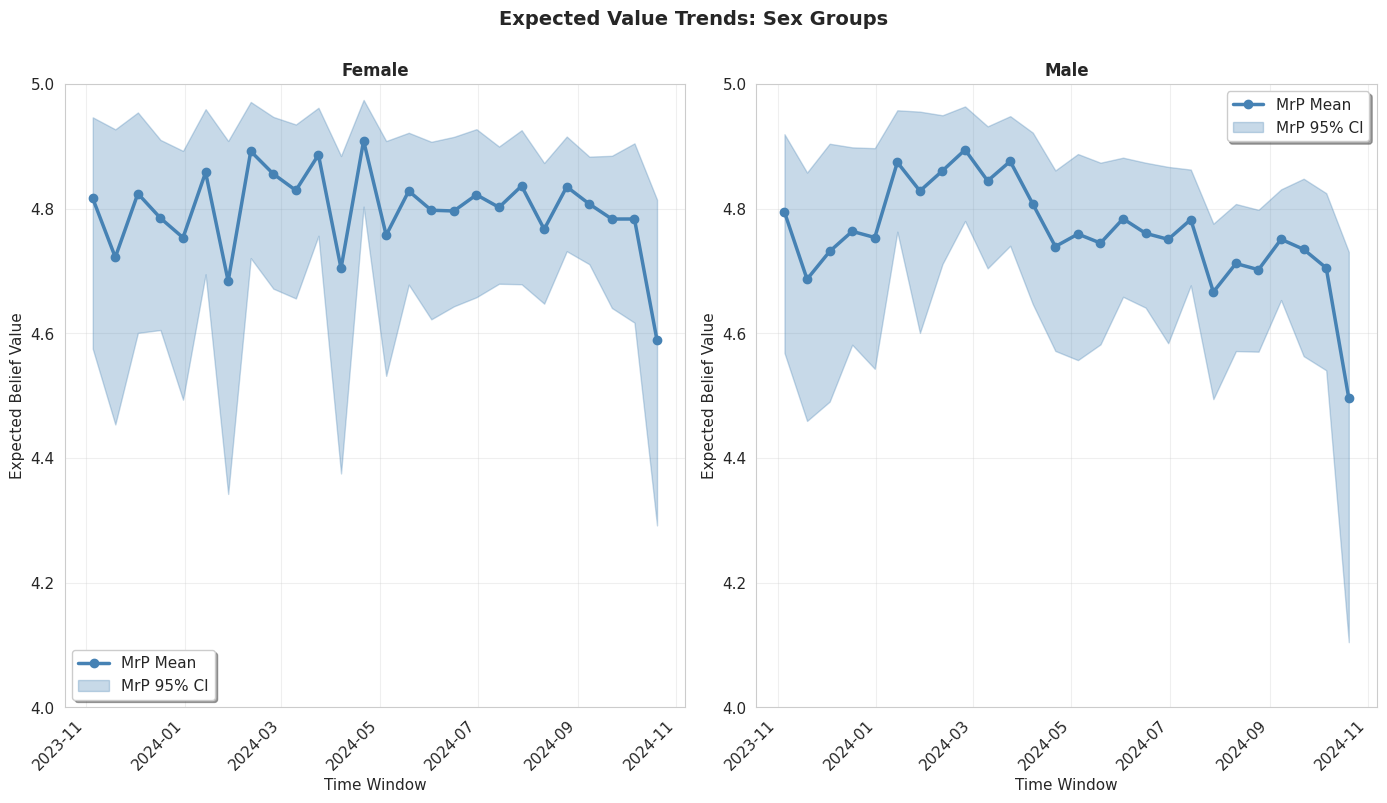

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations/expected_value_trends_age.png


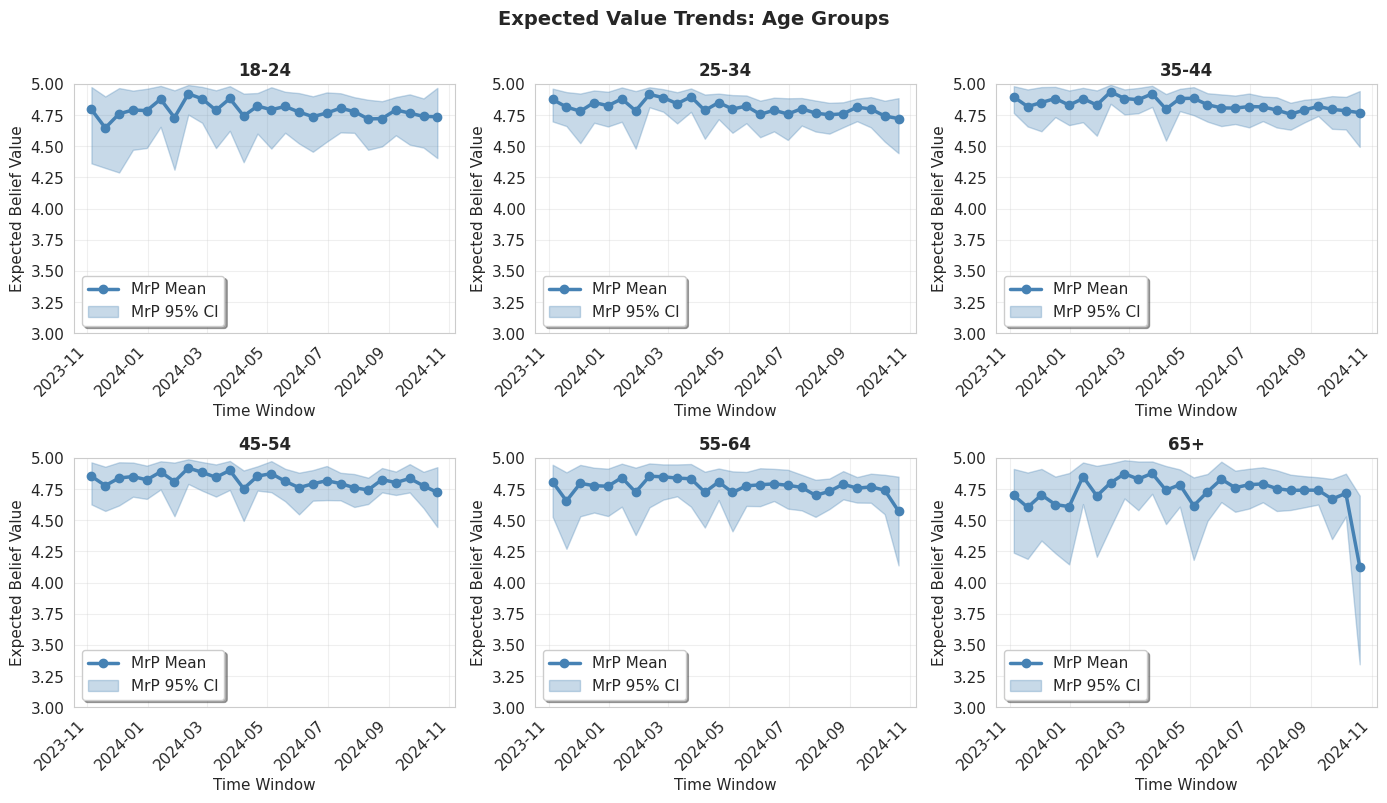

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations/expected_value_trends_vote.png


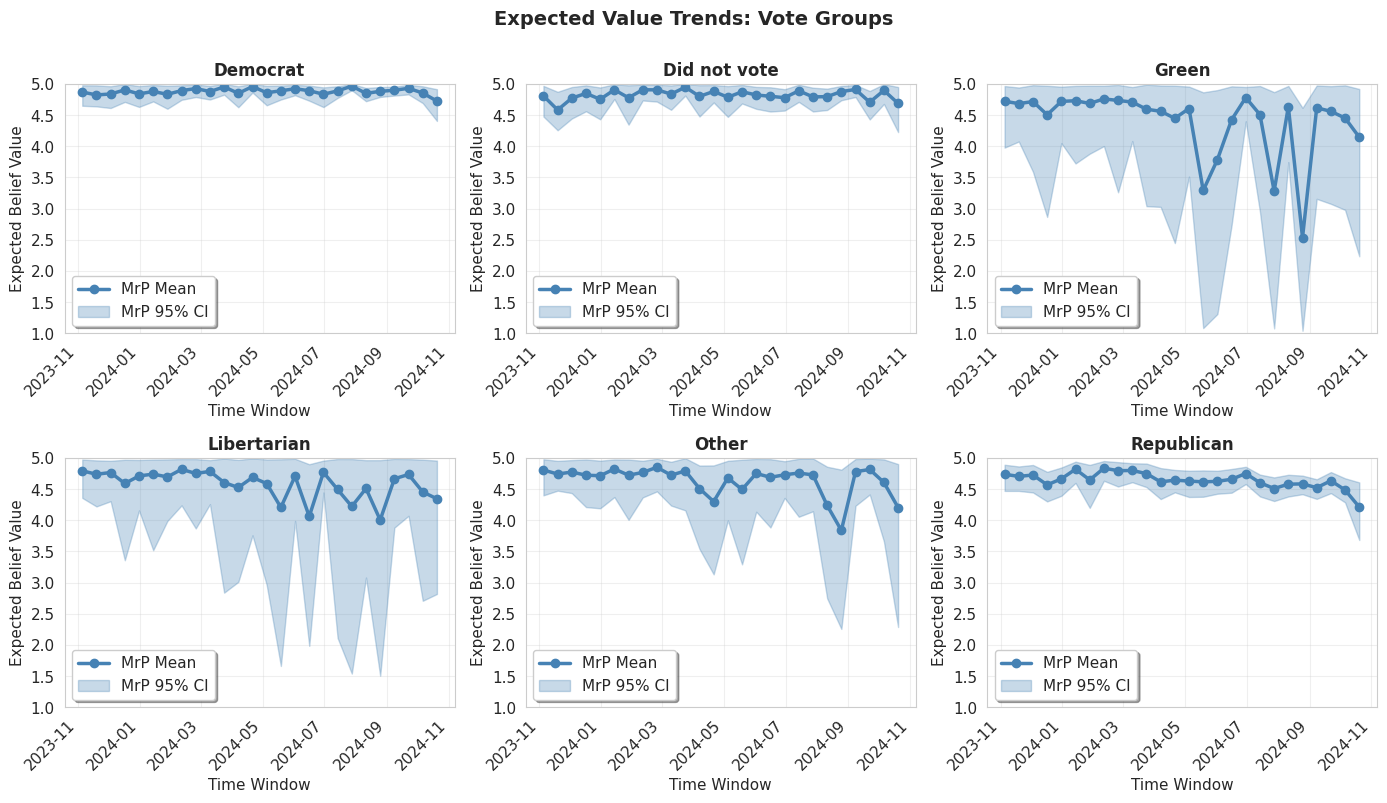

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations/expected_value_trends_income_selected.png


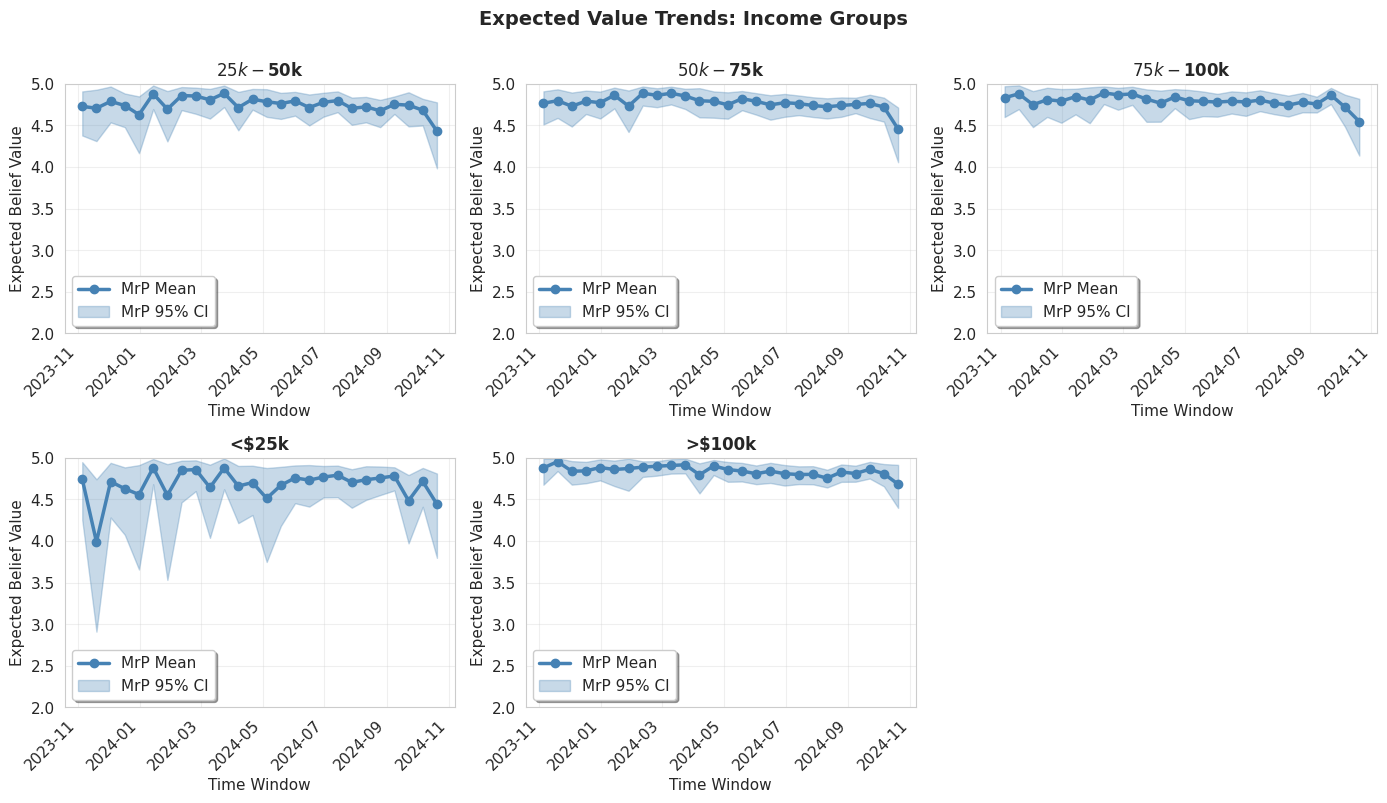

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations/expected_value_trends_eth_selected.png


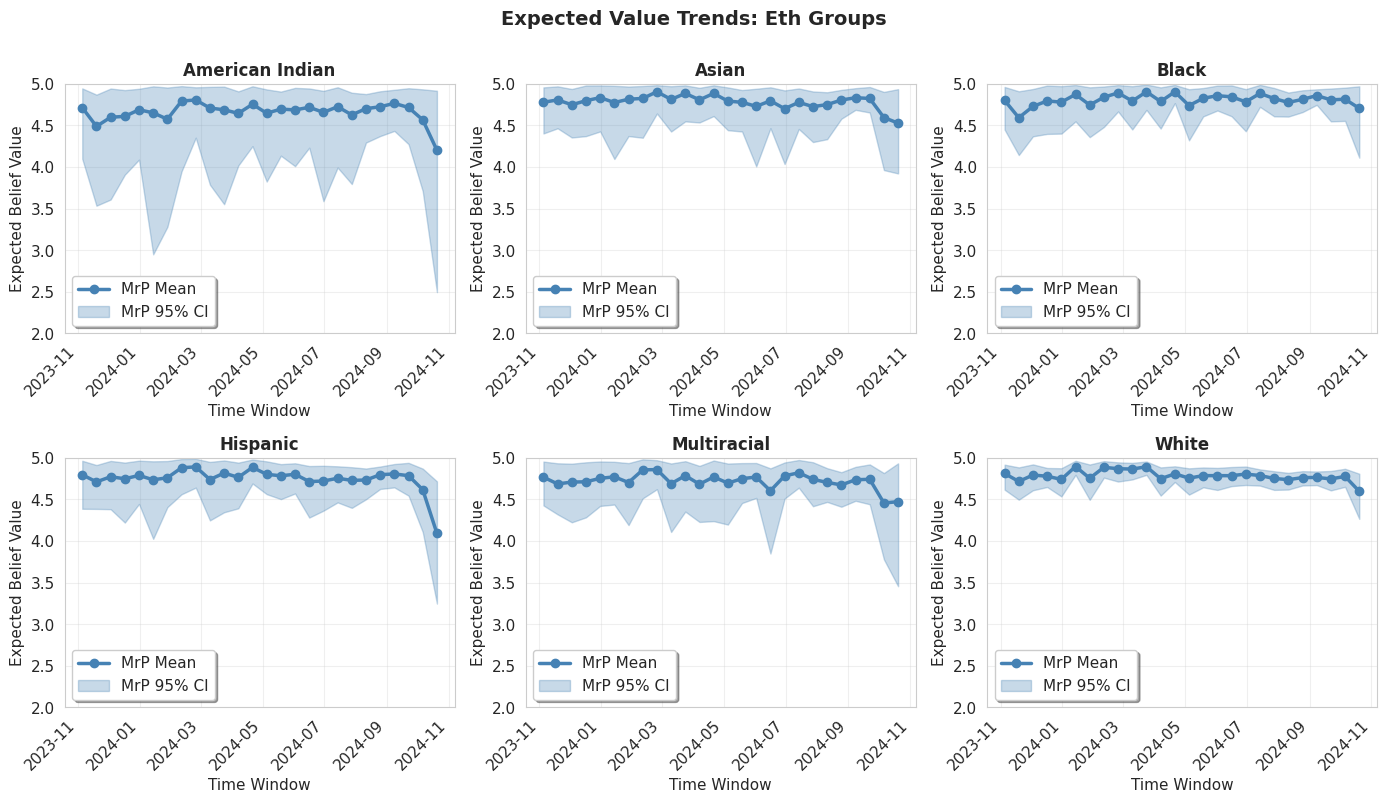

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations/expected_value_trends_education_selected.png


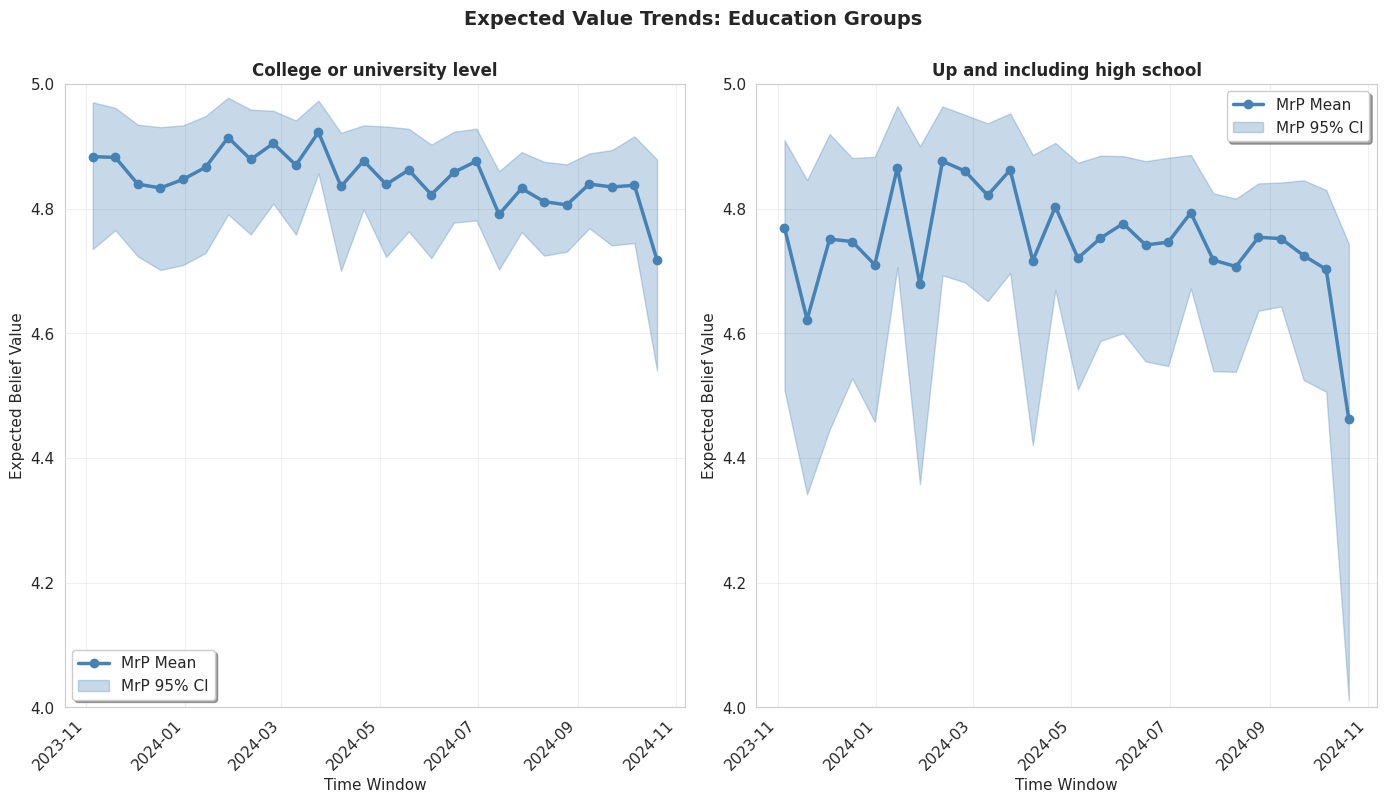


All plots saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations


In [14]:
# Create output directory for plots
plots_dir = f"{base_dir}/visualizations"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots will be saved to: {plots_dir}\n")

# Plot expected value trends by sex
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='sex',
    figsize=(14, 8),
    ncols=2,
    save_path=f"{plots_dir}/expected_value_trends_sex.png"
)

# Plot expected value trends by age
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='age',
    figsize=(14, 8),
    ncols=3,
    save_path=f"{plots_dir}/expected_value_trends_age.png"
)

# Plot expected value trends by vote
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='vote',
    figsize=(14, 8),
    ncols=3,
    save_path=f"{plots_dir}/expected_value_trends_vote.png"
)

# Plot expected value trends by income (selected groups)
plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='income',
    figsize=(14, 8),
    ncols=3,
    save_path=f"{plots_dir}/expected_value_trends_income_selected.png"
)

# Plot expected value trends by ethnicity
plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='eth',
    figsize=(14, 8),
    ncols=3,
    save_path=f"{plots_dir}/expected_value_trends_eth_selected.png"
)

# Plot expected value trends by education
plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='education',
    figsize=(14, 8),
    ncols=2,
    save_path=f"{plots_dir}/expected_value_trends_education_selected.png"
)

print(f"\nAll plots saved to: {plots_dir}")

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations/category_probabilities_sex.png


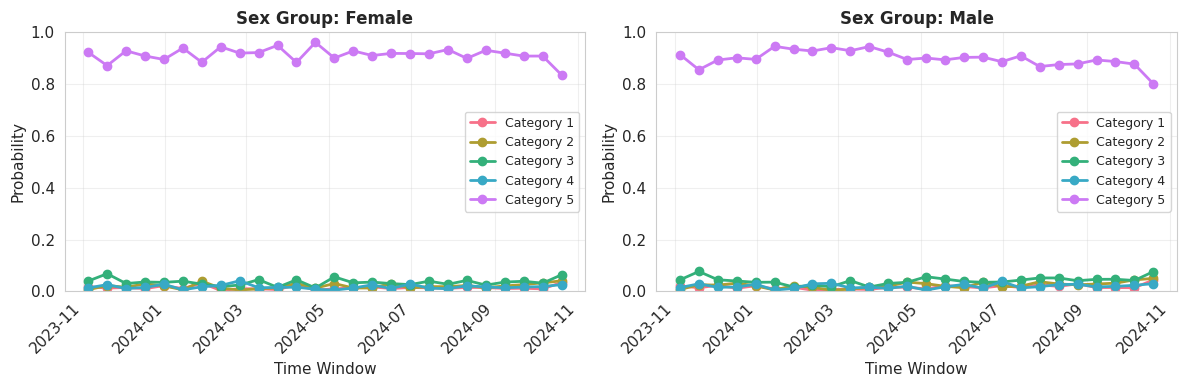

In [15]:
# Category probabilities over time by sex
if 'sex' in group_data:
    plot_category_timeseries(
        group_data['sex'], 
        group_col='sex_idx',
        title_prefix="Sex Group: ",
        figsize=(12, 4),
        ncols=2,
        save_path=f"{plots_dir}/category_probabilities_sex.png"
    )

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol/visualizations/category_stacked_area_vote.png


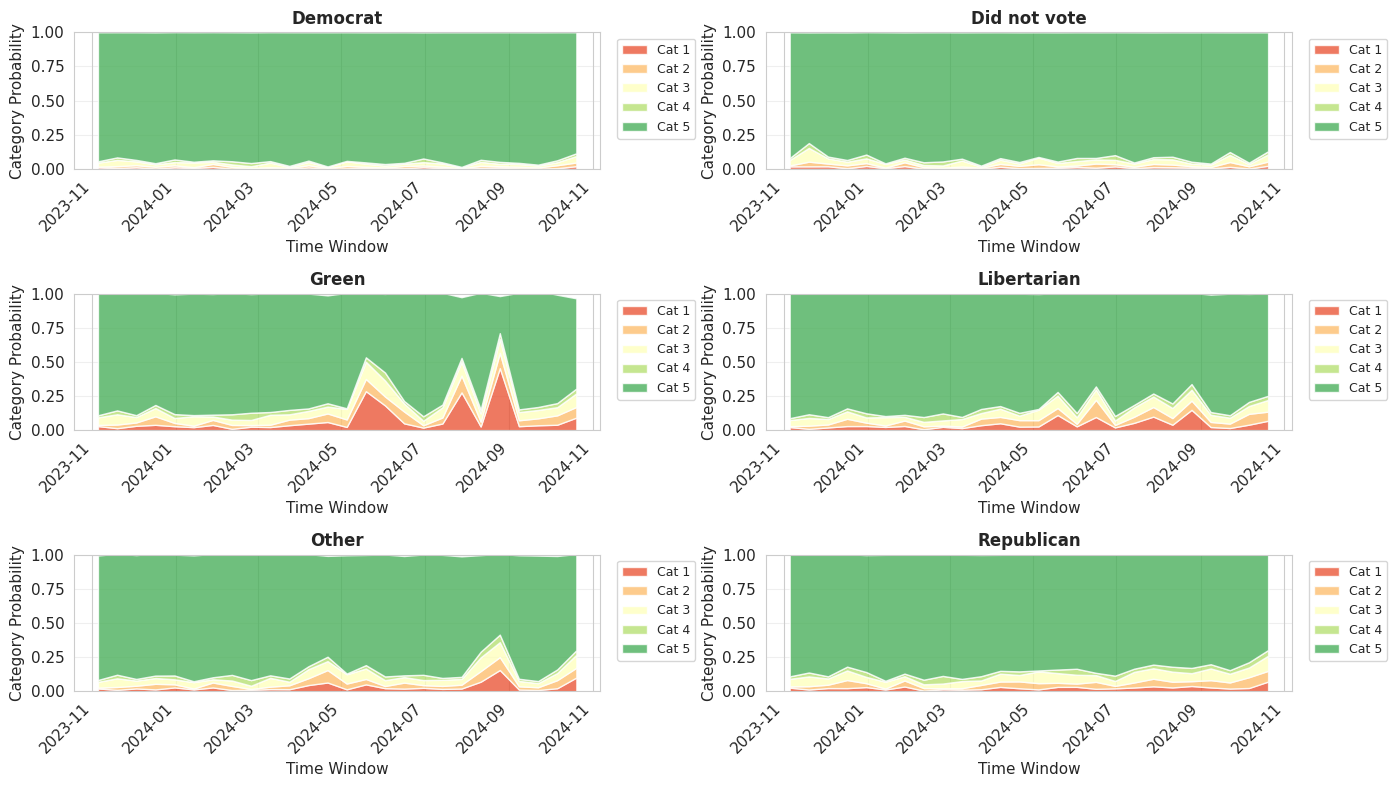

In [16]:
# Stacked area plot for past vote groups
if 'vote' in group_data:
    plot_category_stacked_area(
        group_data['vote'],
        group_col='vote_idx',
        figsize=(14, 8),
        ncols=2,
        save_path=f"{plots_dir}/category_stacked_area_vote.png"
    )


# ANES Clean up

In [17]:
anes2024 = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/original_data/anes_timeseries_2024_csv_20250808/anes_timeseries_2024_csv_20250808.csv")
anes2024

/tmp/ipykernel_150701/408528771.py:1: DtypeWarning: Columns (8,10,11,16,18,19,20,22,23,24,26,27,28,30,31,36,38,39,1448,1449,1450,1451,1452,1455,1456,1457,1458,1459,1463,1464,1465) have mixed types. Specify dtype option on import or set low_memory=False.
  anes2024 = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/original_data/anes_timeseries_2024_csv_20250808/anes_timeseries_2024_csv_20250808.csv")


,version,V240001,V200001,V160001_orig,V240002a,V240002b,V240002c,V240003,V240101a,V240101b,...,V245009,V245010,V245011,V245012,V245013,V245014,V245015,V245016,V245017,V245018
0,ANES2024TimeSeries_20250808,140001,200015,401318,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
1,ANES2024TimeSeries_20250808,140002,200022,300261,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
2,ANES2024TimeSeries_20250808,140003,200039,400181,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
3,ANES2024TimeSeries_20250808,140004,200046,300171,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
4,ANES2024TimeSeries_20250808,140005,200053,405145,2,2,2,1,,,...,-1,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5516,ANES2024TimeSeries_20250808,399764,-1,-1,1,-6,1,3,0.117236,,...,0,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
5517,ANES2024TimeSeries_20250808,399815,-1,-1,1,5,2,3,1.501748,1.15260127111406,...,1,IWER76,1960,3,0,1,5,0,1,0
5518,ANES2024TimeSeries_20250808,399830,-1,-1,1,-6,1,3,1.114477,,...,2,-1. Inapplicable,-1,-1,-1,-1,-1,-1,-1,-1
5519,ANES2024TimeSeries_20250808,399841,-1,-1,4,4,2,3,1.179447,1.1924221171493,...,2,IWER75,1950,3,0,1,5,0,1,2


In [23]:
anes2024['V241550']

0       1
1       2
2       2
3       1
4       1
       ..
5516    2
5517    2
5518    2
5519    1
5520    2
Name: V241550, Length: 5521, dtype: int64

In [24]:
# label clean up 

letin_map = {
    "Increased a lot": 1,
    "Increased a little": 2,
    "Remain the same as it is": 3,
    "Reduced a little": 4,
    "Reduced a lot": 5
}

gss["letin_num"] = gss["letin1a"].map(letin_map)
gss_clean = gss.dropna(subset=["letin_num"]).copy()


# Normalize sex values to title case (Male, Female)
gss_clean["sex"] = gss_clean["sex"].str.capitalize()

# Normalize age to age bins
gss_clean["age_num"] = pd.to_numeric(gss_clean["age"], errors="coerce")

age_bins = [18, 25, 35, 45, 55, 65, np.inf]
age_labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

# Create age group variable
gss_clean["age"] = pd.cut(
    gss_clean["age_num"],
    bins=age_bins,
    labels=age_labels,
    right=False,      # include left endpoint, exclude right
    include_lowest=True
)

# Normalize income to bins
def extract_income_lower(income_str):
    if pd.isna(income_str):
        return np.nan
    # Remove $ and commas
    income_str = income_str.replace("$", "").replace(",", "")
    # Match first number
    match = re.match(r"(\d+)", income_str)
    if match:
        return float(match.group(1))
    return np.nan

gss_clean = gss_clean.copy()
gss_clean["income_num"] = gss_clean["income16"].apply(extract_income_lower)
income_bins = [0, 25000, 50000, 75000, 100000, np.inf]
income_labels = [
    "<$25k",
    "$25k-$50k",
    "$50k-$75k",
    "$75k-$100k",
    ">$100k"
]
gss_clean.loc[:, "income"] = pd.cut(
    gss_clean["income_num"],
    bins=income_bins,
    labels=income_labels,
    right=False,
    include_lowest=True
)

# Normalize past vote to simplified categories
vote_align_map = {
    "Biden": "Democrat",      
    "Trump": "Republican",     
}

gss_clean.loc[:, "vote"] = gss_clean["pres20"].map(vote_align_map)


# Map education categories
edu_align_map = {
    "High school": "Up and including high school",
    "Less than high school": "Up and including high school",
    "Bachelor's": "Colledge or university level",
    "Graduate": "College or university level",
    "Associate/junior college": "Colledge or university level",
    ".d:  Do not Know/Cannot Choose": np.nan
}
gss_clean.loc[:, "education"] = gss_clean["degree"].map(edu_align_map)

gss_clean

,year,id_,age,degree,sex,partyid,letin1a,racecen1,racecen2,dateintv,ballot,income16,pres20,letin_num,age_num,income_num,income,vote,education
0,2024,1,25-34,Bachelor's,Male,Not very strong democrat,Reduced a little,Black or African American,.i: Inapplicable,927,Ballot b,"$110,000 to $129,999",Biden,4.0,33.0,110000.0,>$100k,Democrat,Colledge or university level
1,2024,2,55-64,Graduate,Male,Strong democrat,Reduced a little,White,.i: Inapplicable,619,Ballot b,"$60,000 to $74,999",Biden,4.0,64.0,60000.0,$50k-$75k,Democrat,College or university level
2,2024,3,65+,Associate/junior college,Female,Strong democrat,Remain the same as it is,White,.i: Inapplicable,621,Ballot c,"$110,000 to $129,999",Biden,3.0,69.0,110000.0,>$100k,Democrat,Colledge or university level
4,2024,5,65+,High school,Female,"Independent (neither, no response)",Reduced a lot,White,.i: Inapplicable,921,Ballot c,"$60,000 to $74,999",Trump,5.0,70.0,60000.0,$50k-$75k,Republican,Up and including high school
5,2024,6,45-54,Associate/junior college,Male,"Independent (neither, no response)",Reduced a lot,Hispanic,.i: Inapplicable,731,Ballot b,"$7,000 to $7,999",.i: Inapplicable,5.0,53.0,7000.0,<$25k,NaN,Colledge or university level
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3304,2024,3305,65+,Graduate,Male,Not very strong democrat,Increased a little,White,.i: Inapplicable,428,Ballot c,"$4,000 to $4,999",Biden,2.0,84.0,4000.0,<$25k,Democrat,College or university level
3305,2024,3306,65+,High school,Male,"Independent, close to democrat",Remain the same as it is,White,.i: Inapplicable,423,Ballot a,"$75,000 to $89,999",Biden,3.0,68.0,75000.0,$75k-$100k,Democrat,Up and including high school
3306,2024,3307,65+,High school,Female,"Independent (neither, no response)",Reduced a lot,White,.i: Inapplicable,730,Ballot a,"$50,000 to $59,999",.i: Inapplicable,5.0,74.0,50000.0,$50k-$75k,NaN,Up and including high school
3307,2024,3308,45-54,Graduate,Female,"Independent, close to democrat",Remain the same as it is,White,.i: Inapplicable,1020,Ballot b,"$75,000 to $89,999",Biden,3.0,51.0,75000.0,$75k-$100k,Democrat,College or university level


In [25]:
# Update ethnicity mapping: use racecen2 to identify multiracial respondents
eth_align_map = {
    "White": "White",
    "Black or African American": "Black",
    "American Indian or Alaska Native": "American Indian",
    "Asian Indian": "Asian",
    "Chinese": "Asian",
    "Filipino": "Asian",
    "Japanese": "Asian",
    "Korean": "Asian",
    "Vietnamese": "Asian",
    "Other Asian": "Asian",
    "Other Pacific Islander": "Asian",
    "Some other race": "Multiracial",
    "Hispanic": "Hispanic"
}

# Base ethnicity from racecen1
gss_clean.loc[:, "eth"] = gss_clean["racecen1"].map(eth_align_map)

# If racecen2 has a valid second-race answer, force Multiracial
invalid_racecen2 = {
    ".i:  Inapplicable",
    "Some other race",
    ".n:  No answer",
    ".d:  Do not Know/Cannot Choose",
    ".s:  Skipped on Web"
}

racecen2_clean = gss_clean["racecen2"].astype(str).str.strip()
valid_second_race_mask = gss_clean["racecen2"].notna() & (~racecen2_clean.isin(invalid_racecen2))
gss_clean.loc[valid_second_race_mask, "eth"] = "Multiracial"

gss_clean[["racecen1", "racecen2", "eth"]].head()

,racecen1,racecen2,eth
0,Black or African American,.i: Inapplicable,Black
1,White,.i: Inapplicable,White
2,White,.i: Inapplicable,White
4,White,.i: Inapplicable,White
5,Hispanic,.i: Inapplicable,Hispanic


In [26]:
# map gss dateintv to time windows

def convert_dateintv_to_datetime(dateintv):
    """
    Convert GSS dateintv format (MMDD) to datetime.
    """
    if pd.isna(dateintv):
        return pd.NaT
    
    # Coerce non-numeric entries (e.g., ".n:  No answer") to NaT
    if isinstance(dateintv, str):
        digits = re.sub(r"\D", "", dateintv)
        if digits == "":
            return pd.NaT
        dateintv = digits
    
    dateintv_num = pd.to_numeric(dateintv, errors="coerce")
    if pd.isna(dateintv_num):
        return pd.NaT
    
    dateintv_str = str(int(dateintv_num)).zfill(4)  # Ensure 4 digits (e.g., '0427' for April 27)
    month = int(dateintv_str[:2])
    day = int(dateintv_str[2:])
    
    # Determine year based on context 
    year = 2024
    
    try:
        return pd.to_datetime(f"{year}-{month:02d}-{day:02d}")
    except:
        return pd.NaT

def assign_time_window(date, time_windows):
    """
    Assign a date to the appropriate time window.
    Returns the time_window_start string that the date falls into.
    """
    if pd.isna(date):
        return None
    
    # Convert time_windows to datetime if they're strings
    time_window_dt = [pd.to_datetime(tw) for tw in time_windows]
    
    # Make date timezone-aware if time_windows are timezone-aware
    if time_window_dt and time_window_dt[0].tz is not None:
        if date.tz is None:
            date = date.tz_localize('UTC')
    
    # Find the appropriate window
    for i, window_start in enumerate(time_window_dt):
        if i < len(time_window_dt) - 1:
            window_end = time_window_dt[i + 1]
            if window_start <= date < window_end:
                return time_windows[i]
        else:
            # Last window extends to infinity
            if date >= window_start:
                return time_windows[i]
    
    return None

In [27]:
# Distribution of immigration preference (letin_num) by time window
# Uses gss_clean + date/window mapping helpers from cell 20

# Build time windows if missing
if 'time_windows' not in globals():
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([
        d.replace(f"{belief_col}_", "")
        for d in time_window_dirs
    ])

# Sanitize and keep only parseable time-window strings
time_windows_clean = []
for tw in time_windows:
    tw_str = str(tw)
    tw_str = re.sub(r'_(stan|vglmer)_output$', '', tw_str)
    tw_dt = pd.to_datetime(tw_str, errors='coerce')
    if not pd.isna(tw_dt):
        time_windows_clean.append(tw_str)

time_windows_clean = sorted(set(time_windows_clean))

gss_dist = gss_clean.copy()
gss_dist['interview_date'] = gss_dist['dateintv'].apply(convert_dateintv_to_datetime)
gss_dist['time_window_start'] = gss_dist['interview_date'].apply(
    lambda x: assign_time_window(x, time_windows_clean)
 )

# Keep only rows with valid outcome and assigned time window
gss_dist_valid = gss_dist.dropna(subset=['letin_num', 'time_window_start']).copy()
gss_dist_valid['letin_num'] = gss_dist_valid['letin_num'].astype(int)

# Label mapping for readability
choice_label_map = {
    1: 'Increased a lot',
    2: 'Increased a little',
    3: 'Remain the same as it is',
    4: 'Reduced a little',
    5: 'Reduced a lot'
}

# Count responses by (time window, choice)
window_choice_counts = (
    gss_dist_valid
    .groupby(['time_window_start', 'letin_num'])
    .size()
    .reset_index(name='count')
)

# Ensure each window has all 5 categories (missing -> 0)
all_windows = sorted(gss_dist_valid['time_window_start'].unique(), key=lambda x: pd.to_datetime(x))
all_choices = [1, 2, 3, 4, 5]
full_index = pd.MultiIndex.from_product(
    [all_windows, all_choices],
    names=['time_window_start', 'letin_num']
 )

window_choice_counts = (
    window_choice_counts
    .set_index(['time_window_start', 'letin_num'])
    .reindex(full_index, fill_value=0)
    .reset_index()
 )

# Percent within each time window
window_totals = window_choice_counts.groupby('time_window_start')['count'].transform('sum')
window_choice_counts['percentage'] = np.where(
    window_totals > 0,
    (window_choice_counts['count'] / window_totals * 100).round(2),
    np.nan
)

window_distribution = window_choice_counts.copy()
window_distribution['choice_label'] = window_distribution['letin_num'].map(choice_label_map)
window_distribution = window_distribution[[
    'time_window_start', 'letin_num', 'choice_label', 'count', 'percentage'
]]

print(f"Valid responses with assigned window: {len(gss_dist_valid)}")
print(f"Usable time windows: {len(all_windows)}")
display(window_distribution)

Valid responses with assigned window: 3187
Usable time windows: 16


,time_window_start,letin_num,choice_label,count,percentage
0,2024-03-24 00:00:00+00:00,1,Increased a lot,0,0.00
1,2024-03-24 00:00:00+00:00,2,Increased a little,1,20.00
2,2024-03-24 00:00:00+00:00,3,Remain the same as it is,1,20.00
3,2024-03-24 00:00:00+00:00,4,Reduced a little,0,0.00
4,2024-03-24 00:00:00+00:00,5,Reduced a lot,3,60.00
...,...,...,...,...,...
75,2024-10-20 00:00:00+00:00,1,Increased a lot,34,6.23
76,2024-10-20 00:00:00+00:00,2,Increased a little,51,9.34
77,2024-10-20 00:00:00+00:00,3,Remain the same as it is,191,34.98
78,2024-10-20 00:00:00+00:00,4,Reduced a little,109,19.96


Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/gss_national_stacked_area_time_window.png


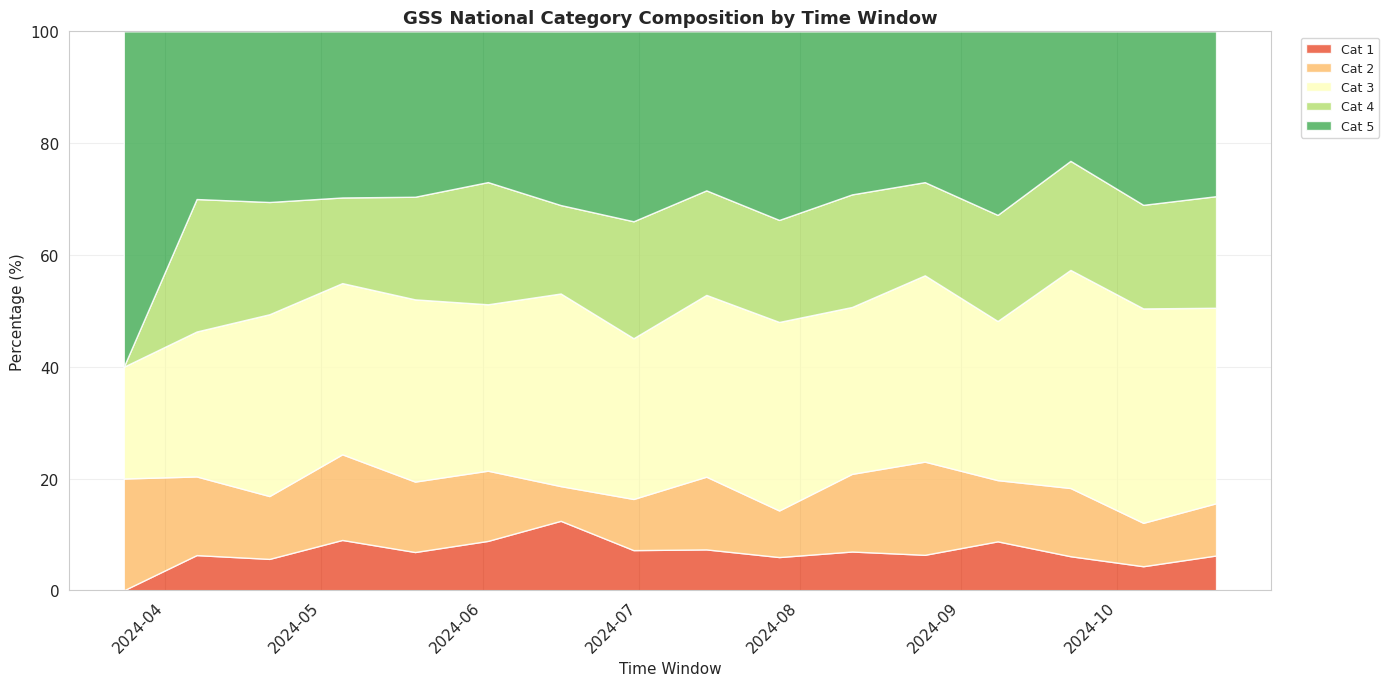

letin_num,1,2,3,4,5
time_window_start,,,,,
2024-03-24 00:00:00+00:00,0.00,20.00,20.00,0.00,60.00
2024-04-07 00:00:00+00:00,6.30,14.07,25.93,23.70,30.00
2024-04-21 00:00:00+00:00,5.62,11.24,32.53,20.08,30.52
2024-05-05 00:00:00+00:00,9.01,15.32,30.63,15.32,29.73
2024-05-19 00:00:00+00:00,6.85,12.60,32.60,18.36,29.59


In [28]:
# National-level GSS category composition per time window (stacked area)
gss_plot_data = None

# Reuse if already built in previous cell
if 'window_distribution' in globals() and len(window_distribution) > 0:
    gss_plot_data = window_distribution.copy()
else:
    # Build from gss_clean if needed
    if 'time_windows' not in globals():
        time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
        time_windows = sorted([d.replace(f"{belief_col}_", "") for d in time_window_dirs])

    time_windows_clean = []
    for tw in time_windows:
        tw_str = str(tw)
        tw_str = re.sub(r'_(stan|vglmer)_output$', '', tw_str)
        tw_dt = pd.to_datetime(tw_str, errors='coerce')
        if not pd.isna(tw_dt):
            time_windows_clean.append(tw_str)

    gss_tmp = gss_clean.copy()
    gss_tmp['interview_date'] = gss_tmp['dateintv'].apply(convert_dateintv_to_datetime)
    gss_tmp['time_window_start'] = gss_tmp['interview_date'].apply(
        lambda x: assign_time_window(x, sorted(set(time_windows_clean)))
    )
    gss_tmp = gss_tmp.dropna(subset=['letin_num', 'time_window_start']).copy()
    gss_tmp['letin_num'] = gss_tmp['letin_num'].astype(int)

    gss_plot_data = (
        gss_tmp.groupby(['time_window_start', 'letin_num'])
        .size()
        .reset_index(name='count')
    )
    totals = gss_plot_data.groupby('time_window_start')['count'].transform('sum')
    gss_plot_data['percentage'] = np.where(totals > 0, gss_plot_data['count'] / totals * 100, np.nan)

# Pivot to wide matrix: rows=time windows, cols=categories
gss_pivot = (
    gss_plot_data.pivot(index='time_window_start', columns='letin_num', values='percentage')
    .fillna(0)
    .sort_index(key=lambda s: pd.to_datetime(s, errors='coerce'))
 )

# Ensure category order 1..5 if present
cat_order = [c for c in [1, 2, 3, 4, 5] if c in gss_pivot.columns]
gss_pivot = gss_pivot[cat_order]

# Plot stacked area (%)
fig, ax = plt.subplots(figsize=(14, 7))
colors = sns.color_palette("RdYlGn", n_colors=len(gss_pivot.columns))
ax.stackplot(
    pd.to_datetime(gss_pivot.index),
    *[gss_pivot[c].values for c in gss_pivot.columns],
    labels=[f"Cat {c}" for c in gss_pivot.columns],
    colors=colors,
    alpha=0.85
 )
ax.set_title("GSS National Category Composition by Time Window", fontsize=13, fontweight='bold')
ax.set_xlabel('Time Window')
ax.set_ylabel('Percentage (%)')
ax.set_ylim(0, 100)
ax.grid(True, axis='y', alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Save
gss_plots_dir = f"{base_dir}/gss_visualizations"
os.makedirs(gss_plots_dir, exist_ok=True)
gss_nat_plot_path = f"{gss_plots_dir}/gss_national_stacked_area_time_window.png"
plt.savefig(gss_nat_plot_path, dpi=300, bbox_inches='tight')
print(f"Saved: {gss_nat_plot_path}")
plt.show()

gss_pivot.head()

In [29]:
def prepare_gss_bootstrap_data(gss_data, group_col, time_windows, outcome_col='letin_num', n_bootstrap=250):
    """
    Prepare GSS data with bootstrap distributions
    Stores all bootstrap means for each (group, window) combination.
    
    Parameters:
    - gss_data: GSS dataframe with dateintv column
    - group_col: Column name for demographic group (e.g., 'sex', 'age', 'income', 'vote')
    - time_windows: List of time window start dates (as strings)
    - outcome_col: Column name for outcome variable (default: 'letin_num')
    - n_bootstrap: Number of bootstrap iterations (default: 250)
    
    Returns:
    - gss_summary: DataFrame with observed means and sample sizes
    - bootstrap_distributions: Dict with key (group_val, window) -> list of bootstrap means
    """
    # Create a copy to avoid modifying original data
    gss_copy = gss_data.copy()
    
    # Convert dateintv to datetime
    gss_copy['interview_date'] = gss_copy['dateintv'].apply(convert_dateintv_to_datetime)
    
    # Assign time windows
    gss_copy['time_window_start'] = gss_copy['interview_date'].apply(
        lambda x: assign_time_window(x, time_windows)
    )
    
    # Filter to only rows that fall within time windows and have valid data
    gss_copy = gss_copy.dropna(subset=[group_col, outcome_col, 'time_window_start'])
    
    # Store bootstrap distributions and summary statistics
    bootstrap_distributions = {}
    results = []
    
    for (group_val, window), group_data in gss_copy.groupby([group_col, 'time_window_start']):
        samples = group_data[outcome_col].values
        n_samples = len(samples)
        
        if n_samples == 0:
            continue
        
        # Observed mean
        observed_mean = np.mean(samples)
        
        # Bootstrap resampling - store all means
        bootstrap_means = []
        for _ in range(n_bootstrap):
            bootstrap_sample = np.random.choice(samples, size=n_samples, replace=True)
            bootstrap_means.append(np.mean(bootstrap_sample))
        
        # Store bootstrap distribution
        key = (group_val, window)
        bootstrap_distributions[key] = bootstrap_means
        
        # Store summary
        result = {
            group_col: group_val,
            'time_window_start': window,
            'mean': observed_mean,
            'n': n_samples,
            'sd': np.std(samples)
        }
        results.append(result)
    
    gss_summary = pd.DataFrame(results)
    
    return gss_summary, bootstrap_distributions

def calculate_bootstrap_cis(bootstrap_distributions, gss_summary, group_col):
    """
    Calculate confidence intervals from bootstrap distributions (without moving average).
    
    Parameters:
    - bootstrap_distributions: Dict with (group_val, window) -> list of bootstrap means
    - gss_summary: DataFrame with group and time window info
    - group_col: Name of the group column
    
    Returns:
    - DataFrame with CIs added
    """
    gss_with_cis = gss_summary.copy()
    
    # Calculate confidence intervals at multiple levels
    ci_levels = [68, 80, 90, 95]
    
    for ci_level in ci_levels:
        lower_percentile = (100 - ci_level) / 2
        upper_percentile = 100 - lower_percentile
        
        lower_vals = []
        upper_vals = []
        
        for _, row in gss_with_cis.iterrows():
            key = (row[group_col], row['time_window_start'])
            
            if key in bootstrap_distributions:
                boot_means = np.array(bootstrap_distributions[key])
                lower_vals.append(np.percentile(boot_means, lower_percentile))
                upper_vals.append(np.percentile(boot_means, upper_percentile))
            else:
                lower_vals.append(np.nan)
                upper_vals.append(np.nan)
        
        gss_with_cis[f'lower_{ci_level}'] = lower_vals
        gss_with_cis[f'upper_{ci_level}'] = upper_vals
    
    return gss_with_cis

In [30]:
# Helper: summary stats per group within each time window

def summarize_counts_by_group_and_window(gss_ts, group_col, window_col='time_window_start', count_col='n'):
    """
    Summarize counts per (window, group) and print min/max/mean/std across all group-window cells.
    Returns a DataFrame with per-window, per-group counts.
    """
    counts = (
        gss_ts.groupby([window_col, group_col])[count_col]
        .sum()
        .reset_index()
    )

    print(f"Sample count stats across {group_col} x window cells:")
    print(counts[count_col].describe())

    return counts

In [31]:
time_window_dirs = [
    d for d in os.listdir(base_dir)
    if d.startswith(belief_col)
    and not d.endswith("vglmer_output")
    and not d.endswith("global.csv")
]
time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                       for d in time_window_dirs])
print("Time windows in predictions:", time_windows)
print(len(time_windows))

Time windows in predictions: ['2023-11-05 00:00:00+00:00', '2023-11-19 00:00:00+00:00', '2023-12-03 00:00:00+00:00', '2023-12-17 00:00:00+00:00', '2023-12-31 00:00:00+00:00', '2024-01-14 00:00:00+00:00', '2024-01-28 00:00:00+00:00', '2024-02-11 00:00:00+00:00', '2024-02-25 00:00:00+00:00', '2024-03-10 00:00:00+00:00', '2024-03-24 00:00:00+00:00', '2024-04-07 00:00:00+00:00', '2024-04-21 00:00:00+00:00', '2024-05-05 00:00:00+00:00', '2024-05-19 00:00:00+00:00', '2024-06-02 00:00:00+00:00', '2024-06-16 00:00:00+00:00', '2024-06-30 00:00:00+00:00', '2024-07-14 00:00:00+00:00', '2024-07-28 00:00:00+00:00', '2024-08-11 00:00:00+00:00', '2024-08-25 00:00:00+00:00', '2024-09-08 00:00:00+00:00', '2024-09-22 00:00:00+00:00', '2024-10-06 00:00:00+00:00', '2024-10-20 00:00:00+00:00']
26


In [32]:
# Prepare GSS data with bootstrap distributions (250 iterations)
gss_ts_sex, gss_boot_sex = prepare_gss_bootstrap_data(gss_clean, 'sex', time_windows)
gss_ts_sex = calculate_bootstrap_cis(gss_boot_sex, gss_ts_sex, 'sex')
gss_ts_sex.head()

,sex,time_window_start,mean,n,sd,lower_68,upper_68,lower_80,upper_80,lower_90,upper_90,lower_95,upper_95
0,.d: do not know/cannot choose,2024-05-19 00:00:00+00:00,3.000000,1,0.000000,3.0,3.000000,3.000000,3.000000,3.000000,3.000000,3.0,3.0
1,.d: do not know/cannot choose,2024-07-14 00:00:00+00:00,1.000000,1,0.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.0
2,.d: do not know/cannot choose,2024-07-28 00:00:00+00:00,3.666667,3,1.247219,3.0,4.666667,2.666667,4.666667,2.666667,4.666667,2.0,5.0
3,.d: do not know/cannot choose,2024-10-20 00:00:00+00:00,5.000000,2,0.000000,5.0,5.000000,5.000000,5.000000,5.000000,5.000000,5.0,5.0
4,.n: no answer,2024-05-05 00:00:00+00:00,4.000000,1,0.000000,4.0,4.000000,4.000000,4.000000,4.000000,4.000000,4.0,4.0


In [33]:
summarize_counts_by_group_and_window(gss_ts_sex, 'sex')

Sample count stats across sex x window cells:
count     41.000000
mean      77.731707
std       68.806985
min        1.000000
25%        4.000000
50%       69.000000
75%      112.000000
max      288.000000
Name: n, dtype: float64


,time_window_start,sex,n
0,2024-03-24 00:00:00+00:00,Female,4
1,2024-03-24 00:00:00+00:00,Male,1
2,2024-04-07 00:00:00+00:00,.s: skipped on web,1
3,2024-04-07 00:00:00+00:00,Female,143
4,2024-04-07 00:00:00+00:00,Male,126
5,2024-04-21 00:00:00+00:00,.s: skipped on web,1
6,2024-04-21 00:00:00+00:00,Female,143
7,2024-04-21 00:00:00+00:00,Male,105
8,2024-05-05 00:00:00+00:00,.n: no answer,1
9,2024-05-05 00:00:00+00:00,Female,60


In [34]:
gss_ts_age, gss_boot_age = prepare_gss_bootstrap_data(gss_clean, 'age', time_windows)
gss_ts_age = calculate_bootstrap_cis(gss_boot_age, gss_ts_age, 'age')
gss_ts_age.head()

/tmp/ipykernel_173698/85621500.py:35: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for (group_val, window), group_data in gss_copy.groupby([group_col, 'time_window_start']):


,age,time_window_start,mean,n,sd,lower_68,upper_68,lower_80,upper_80,lower_90,upper_90,lower_95,upper_95
0,18-24,2024-04-07 00:00:00+00:00,3.409091,22,1.302414,3.136364,3.681818,3.090909,3.772727,2.954545,3.888636,2.828409,3.954545
1,18-24,2024-04-21 00:00:00+00:00,3.470588,17,0.848365,3.235294,3.705882,3.229412,3.705882,3.117647,3.797059,3.117647,3.986765
2,18-24,2024-05-05 00:00:00+00:00,3.571429,7,1.178030,3.142857,4.000000,3.000000,4.142857,2.857143,4.285714,2.714286,4.428571
3,18-24,2024-05-19 00:00:00+00:00,3.043478,23,0.858627,2.862609,3.217391,2.826087,3.260870,2.758696,3.347826,2.695652,3.391304
4,18-24,2024-06-02 00:00:00+00:00,2.500000,16,1.274755,2.187500,2.812500,2.125000,2.937500,2.000000,3.096875,2.000000,3.235938


In [35]:
summarize_counts_by_group_and_window(gss_ts_age, 'age')

Sample count stats across age x window cells:
count     92.000000
mean      33.402174
std       23.815250
min        2.000000
25%       18.750000
50%       25.500000
75%       42.250000
max      117.000000
Name: n, dtype: float64


,time_window_start,age,n
0,2024-03-24 00:00:00+00:00,55-64,2
1,2024-03-24 00:00:00+00:00,65+,3
2,2024-04-07 00:00:00+00:00,18-24,22
3,2024-04-07 00:00:00+00:00,25-34,30
4,2024-04-07 00:00:00+00:00,35-44,49
...,...,...,...
87,2024-10-20 00:00:00+00:00,25-34,92
88,2024-10-20 00:00:00+00:00,35-44,108
89,2024-10-20 00:00:00+00:00,45-54,91
90,2024-10-20 00:00:00+00:00,55-64,82


In [36]:
gss_ts_income, gss_boot_income = prepare_gss_bootstrap_data(gss_clean, 'income', time_windows)
gss_ts_income = calculate_bootstrap_cis(gss_boot_income, gss_ts_income, 'income')
gss_ts_income

/tmp/ipykernel_173698/85621500.py:35: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for (group_val, window), group_data in gss_copy.groupby([group_col, 'time_window_start']):


,income,time_window_start,mean,n,sd,lower_68,upper_68,lower_80,upper_80,lower_90,upper_90,lower_95,upper_95
0,<$25k,2024-03-24 00:00:00+00:00,5.000000,2,0.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
1,<$25k,2024-04-07 00:00:00+00:00,3.574074,54,1.226284,3.425926,3.740741,3.387037,3.777778,3.294444,3.870370,3.226389,3.888889
2,<$25k,2024-04-21 00:00:00+00:00,3.589744,39,1.125872,3.384615,3.743590,3.333333,3.797436,3.293590,3.911538,3.230769,3.968590
3,<$25k,2024-05-05 00:00:00+00:00,3.142857,28,1.245400,2.892857,3.428571,2.857143,3.500000,2.750000,3.571429,2.678571,3.607143
4,<$25k,2024-05-19 00:00:00+00:00,3.449275,69,1.268758,3.304348,3.608696,3.275362,3.639130,3.217391,3.689130,3.165942,3.710145
...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,>$100k,2024-08-25 00:00:00+00:00,3.608696,23,1.310132,3.340870,3.913043,3.217391,3.956522,3.130435,4.086957,3.043478,4.173913
74,>$100k,2024-09-08 00:00:00+00:00,3.343750,32,1.289607,3.125000,3.593750,3.028125,3.656250,2.968750,3.718750,2.819531,3.812500
75,>$100k,2024-09-22 00:00:00+00:00,3.333333,24,1.142609,3.160000,3.583333,3.083333,3.666667,2.977083,3.750000,2.875000,3.791667
76,>$100k,2024-10-06 00:00:00+00:00,3.600000,50,1.077033,3.460000,3.780000,3.420000,3.802000,3.360000,3.860000,3.304500,3.900000


In [37]:
summarize_counts_by_group_and_window(gss_ts_income, 'income')

Sample count stats across income x window cells:
count     78.000000
mean      35.692308
std       23.479921
min        1.000000
25%       20.250000
50%       30.500000
75%       43.250000
max      145.000000
Name: n, dtype: float64


,time_window_start,income,n
0,2024-03-24 00:00:00+00:00,$50k-$75k,1
1,2024-03-24 00:00:00+00:00,<$25k,2
2,2024-03-24 00:00:00+00:00,>$100k,2
3,2024-04-07 00:00:00+00:00,$25k-$50k,56
4,2024-04-07 00:00:00+00:00,$50k-$75k,39
...,...,...,...
73,2024-10-20 00:00:00+00:00,$25k-$50k,87
74,2024-10-20 00:00:00+00:00,$50k-$75k,78
75,2024-10-20 00:00:00+00:00,$75k-$100k,81
76,2024-10-20 00:00:00+00:00,<$25k,80


In [38]:
gss_ts_vote, gss_boot_vote = prepare_gss_bootstrap_data(gss_clean, 'vote', time_windows)
gss_ts_vote = calculate_bootstrap_cis(gss_boot_vote, gss_ts_vote, 'vote')
gss_ts_vote

,vote,time_window_start,mean,n,sd,lower_68,upper_68,lower_80,upper_80,lower_90,upper_90,lower_95,upper_95
0,Democrat,2024-03-24 00:00:00+00:00,2.000000,1,0.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
1,Democrat,2024-04-07 00:00:00+00:00,3.025862,116,1.078482,2.922414,3.129310,2.896552,3.155172,2.840086,3.185776,2.801724,3.222198
2,Democrat,2024-04-21 00:00:00+00:00,2.978022,91,1.109183,2.879121,3.098901,2.846154,3.121978,2.769231,3.148901,2.708242,3.186813
3,Democrat,2024-05-05 00:00:00+00:00,2.950000,40,1.243986,2.771000,3.129000,2.722500,3.200000,2.650000,3.263750,2.586250,3.300000
4,Democrat,2024-05-19 00:00:00+00:00,3.000000,152,1.106203,2.913421,3.085526,2.887500,3.098684,2.861842,3.118421,2.843586,3.149836
5,Democrat,2024-06-02 00:00:00+00:00,3.023256,86,1.181020,2.893488,3.141395,2.836047,3.186047,2.784302,3.227326,2.744186,3.264826
6,Democrat,2024-06-16 00:00:00+00:00,3.000000,74,1.162476,2.889730,3.135135,2.836486,3.162162,2.776351,3.229730,2.729730,3.253716
7,Democrat,2024-06-30 00:00:00+00:00,3.411765,51,1.013177,3.274510,3.568627,3.233333,3.607843,3.176471,3.647059,3.102451,3.686275
8,Democrat,2024-07-14 00:00:00+00:00,3.128205,39,1.244052,2.897436,3.311795,2.820513,3.358974,2.780769,3.424359,2.717949,3.487179
9,Democrat,2024-07-28 00:00:00+00:00,3.022727,88,1.086877,2.909091,3.147727,2.873864,3.181818,2.829545,3.210795,2.809375,3.247443


In [39]:
summarize_counts_by_group_and_window(gss_ts_vote, 'vote')

Sample count stats across vote x window cells:
count     32.000000
mean      63.125000
std       41.709247
min        1.000000
25%       39.000000
50%       52.000000
75%       77.000000
max      181.000000
Name: n, dtype: float64


,time_window_start,vote,n
0,2024-03-24 00:00:00+00:00,Democrat,1
1,2024-03-24 00:00:00+00:00,Republican,2
2,2024-04-07 00:00:00+00:00,Democrat,116
3,2024-04-07 00:00:00+00:00,Republican,63
4,2024-04-21 00:00:00+00:00,Democrat,91
5,2024-04-21 00:00:00+00:00,Republican,70
6,2024-05-05 00:00:00+00:00,Democrat,40
7,2024-05-05 00:00:00+00:00,Republican,39
8,2024-05-19 00:00:00+00:00,Democrat,152
9,2024-05-19 00:00:00+00:00,Republican,108


In [40]:
# Prepare GSS data with bootstrap distributions (250 iterations)
gss_ts_eth, gss_boot_eth = prepare_gss_bootstrap_data(gss_clean, 'eth', time_windows)
gss_ts_eth = calculate_bootstrap_cis(gss_boot_eth, gss_ts_eth, 'eth')
gss_ts_eth.head()

,eth,time_window_start,mean,n,sd,lower_68,upper_68,lower_80,upper_80,lower_90,upper_90,lower_95,upper_95
0,American Indian,2024-04-07 00:00:00+00:00,3.500000,2,1.500000,2.000000,5.000000,2.000000,5.000000,2.000000,5.0,2.0,5.0
1,American Indian,2024-04-21 00:00:00+00:00,3.666667,3,1.247219,3.000000,4.666667,2.666667,4.666667,2.666667,5.0,2.0,5.0
2,American Indian,2024-05-05 00:00:00+00:00,2.750000,4,1.785357,1.750000,3.750000,1.750000,4.000000,1.000000,4.5,1.0,4.5
3,American Indian,2024-05-19 00:00:00+00:00,4.000000,2,1.000000,3.000000,5.000000,3.000000,5.000000,3.000000,5.0,3.0,5.0
4,American Indian,2024-06-02 00:00:00+00:00,3.666667,3,0.471405,3.333333,4.000000,3.333333,4.000000,3.333333,4.0,3.0,4.0


In [41]:
summarize_counts_by_group_and_window(gss_ts_eth, 'eth')

Sample count stats across eth x window cells:
count     87.000000
mean      36.011494
std       61.510350
min        1.000000
25%        6.000000
50%       10.000000
75%       28.500000
max      366.000000
Name: n, dtype: float64


,time_window_start,eth,n
0,2024-03-24 00:00:00+00:00,White,5
1,2024-04-07 00:00:00+00:00,American Indian,2
2,2024-04-07 00:00:00+00:00,Asian,5
3,2024-04-07 00:00:00+00:00,Black,27
4,2024-04-07 00:00:00+00:00,Hispanic,7
...,...,...,...
82,2024-10-20 00:00:00+00:00,Asian,20
83,2024-10-20 00:00:00+00:00,Black,96
84,2024-10-20 00:00:00+00:00,Hispanic,25
85,2024-10-20 00:00:00+00:00,Multiracial,24


In [42]:
# Prepare GSS data with bootstrap distributions (250 iterations)
gss_ts_educ, gss_boot_educ = prepare_gss_bootstrap_data(gss_clean, 'education', time_windows)
gss_ts_educ = calculate_bootstrap_cis(gss_boot_educ, gss_ts_educ, 'education')
gss_ts_educ.head()

,education,time_window_start,mean,n,sd,lower_68,upper_68,lower_80,upper_80,lower_90,upper_90,lower_95,upper_95
0,Colledge or university level,2024-03-24 00:00:00+00:00,2.000000,1,0.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
1,Colledge or university level,2024-04-07 00:00:00+00:00,3.529412,85,1.203800,3.411765,3.660706,3.352941,3.707059,3.305882,3.752941,3.270588,3.792059
2,Colledge or university level,2024-04-21 00:00:00+00:00,3.612500,80,1.209274,3.462500,3.725000,3.425000,3.762500,3.375000,3.826250,3.362500,3.872187
3,Colledge or university level,2024-05-05 00:00:00+00:00,3.093750,32,1.422133,2.875000,3.348750,2.840625,3.437500,2.656250,3.548437,2.562500,3.625000
4,Colledge or university level,2024-05-19 00:00:00+00:00,3.508621,116,1.276415,3.379310,3.629310,3.344828,3.646552,3.296983,3.677155,3.260560,3.730819


In [43]:
summarize_counts_by_group_and_window(gss_ts_educ, 'education')

Sample count stats across education x window cells:
count     48.000000
mean      66.333333
std       56.753792
min        1.000000
25%       26.000000
50%       49.000000
75%       87.250000
max      299.000000
Name: n, dtype: float64


,time_window_start,education,n
0,2024-03-24 00:00:00+00:00,Colledge or university level,1
1,2024-03-24 00:00:00+00:00,College or university level,2
2,2024-03-24 00:00:00+00:00,Up and including high school,2
3,2024-04-07 00:00:00+00:00,Colledge or university level,85
4,2024-04-07 00:00:00+00:00,College or university level,53
5,2024-04-07 00:00:00+00:00,Up and including high school,132
6,2024-04-21 00:00:00+00:00,Colledge or university level,80
7,2024-04-21 00:00:00+00:00,College or university level,51
8,2024-04-21 00:00:00+00:00,Up and including high school,118
9,2024-05-05 00:00:00+00:00,Colledge or university level,32


In [ ]:
# Scatter plot: one dot per (window, age bin)
gss_age_window_counts['time_dt'] = pd.to_datetime(gss_age_window_counts['time_window_start'])
plt.figure(figsize=(10, 5))
plt.scatter(gss_age_window_counts['time_dt'], gss_age_window_counts['n'], alpha=0.7)
plt.title('GSS Sample Counts per Window per Age Bin')
plt.xlabel('Time Window')
plt.ylabel('Sample Count (per age bin)')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



NameError: name 'gss_age_window_counts' is not defined

Plots will be saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/expected_value_trends_sex.png


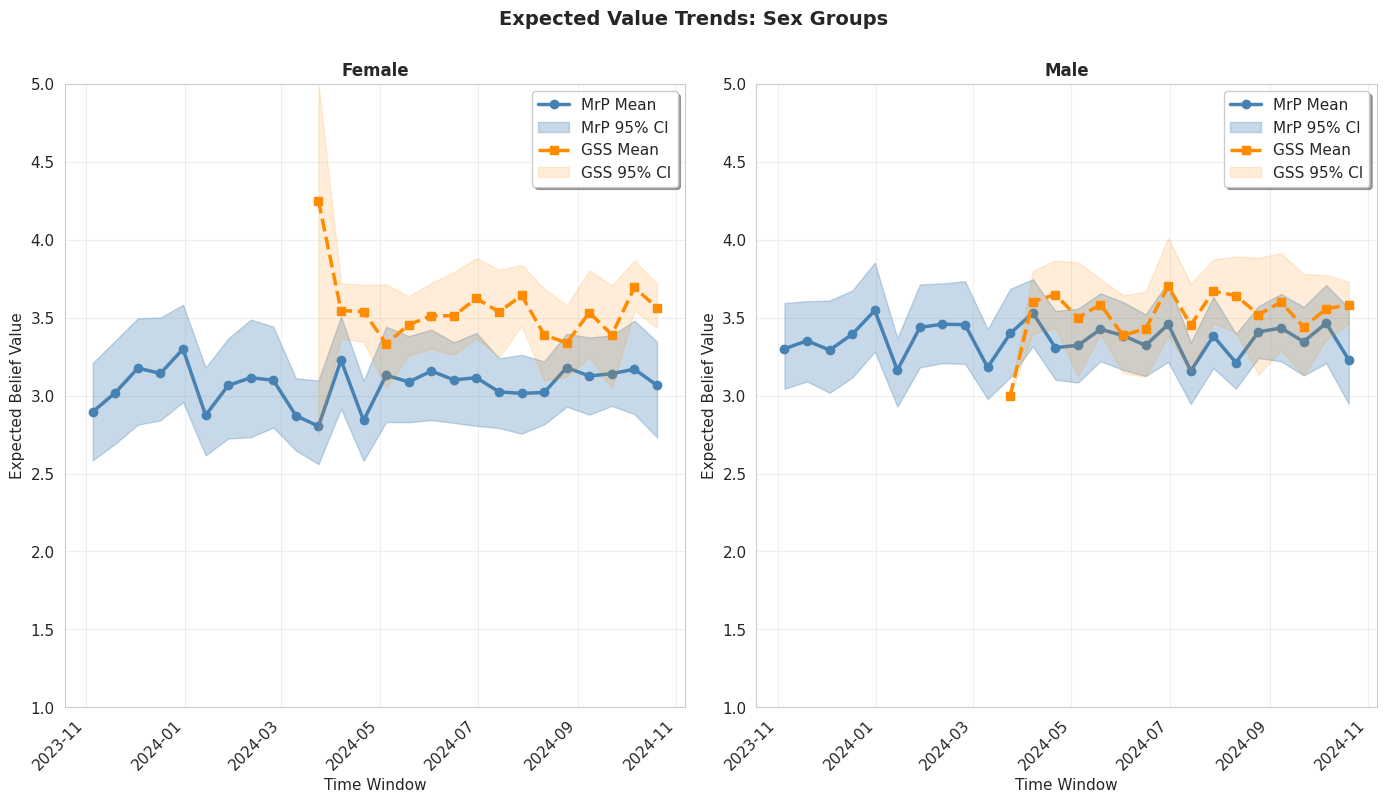

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/expected_value_trends_age.png


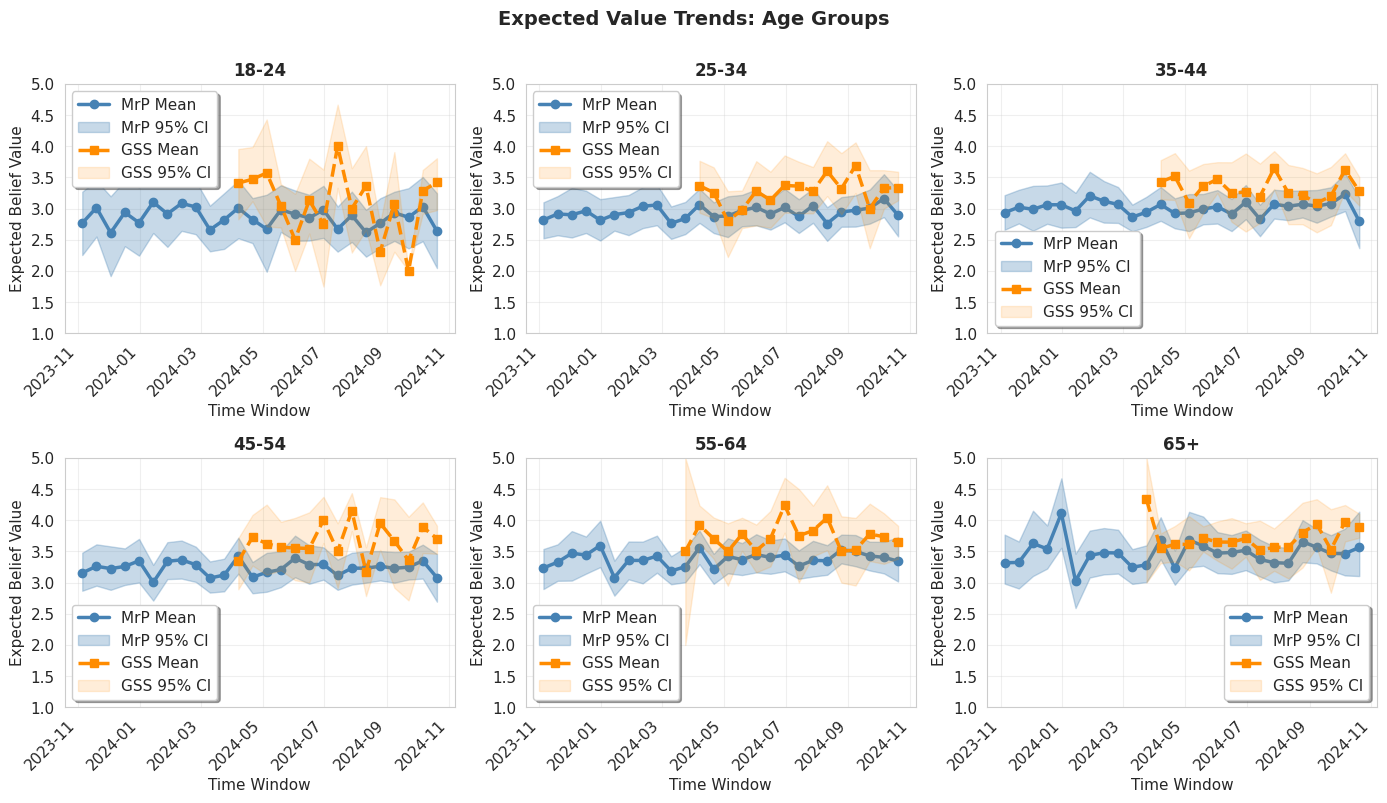

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/expected_value_trends_vote.png


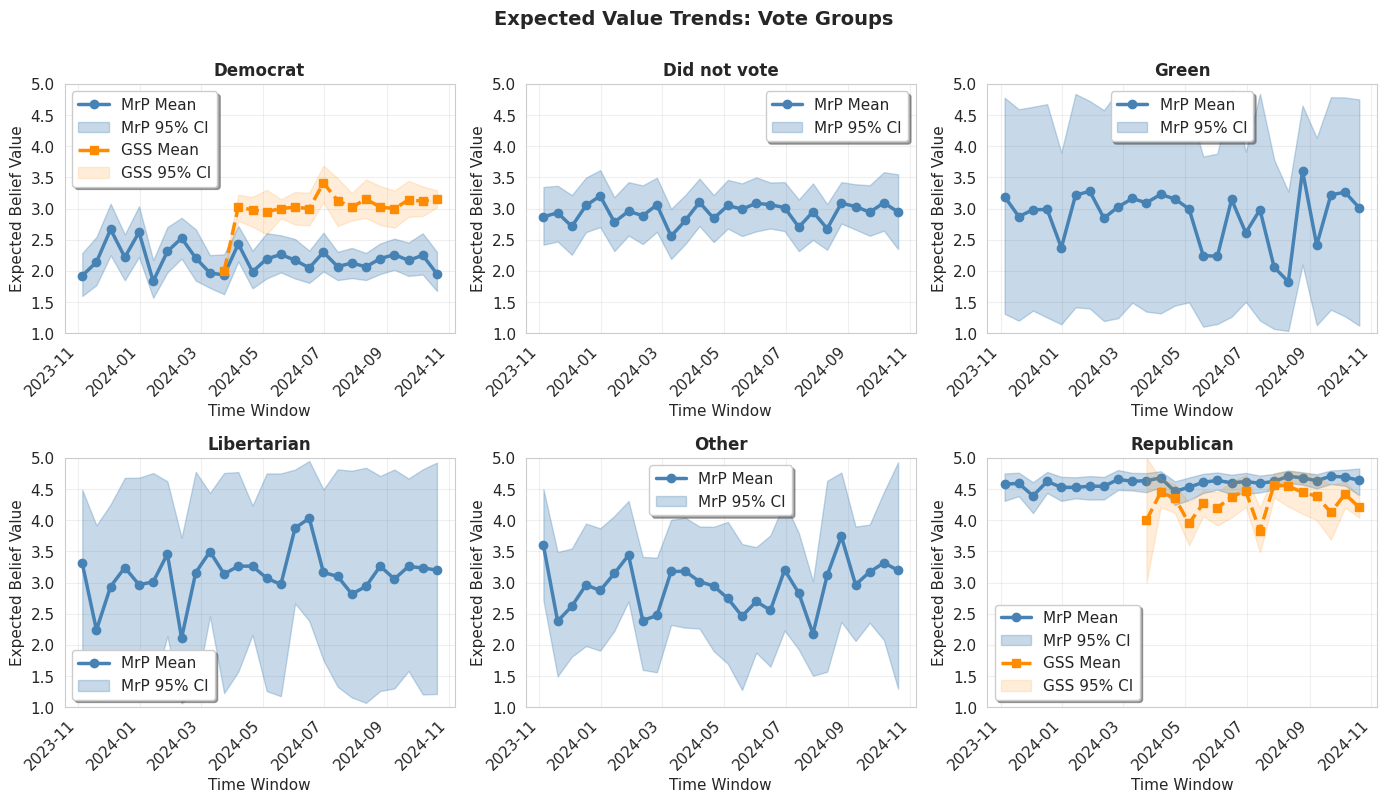

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/expected_value_trends_income.png


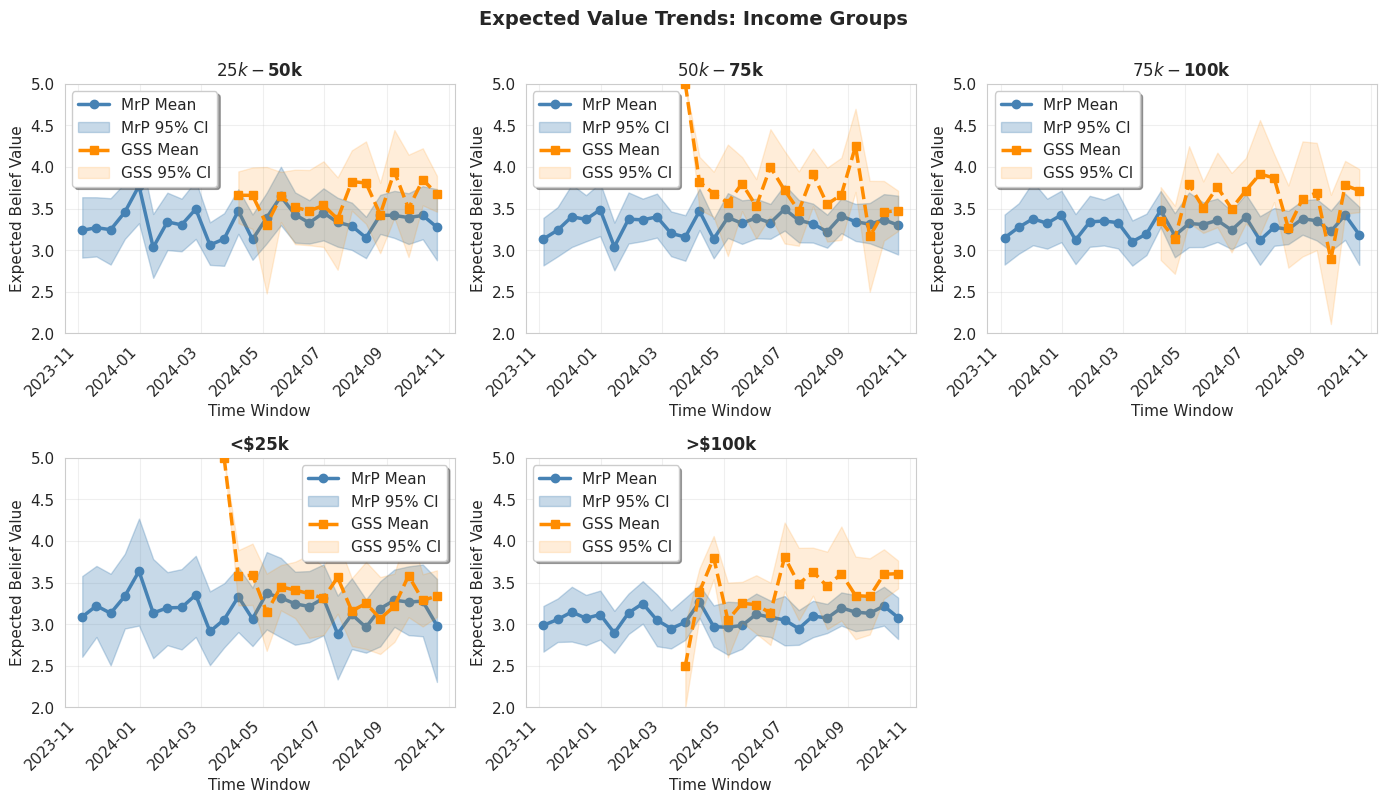

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/expected_value_trends_eth.png


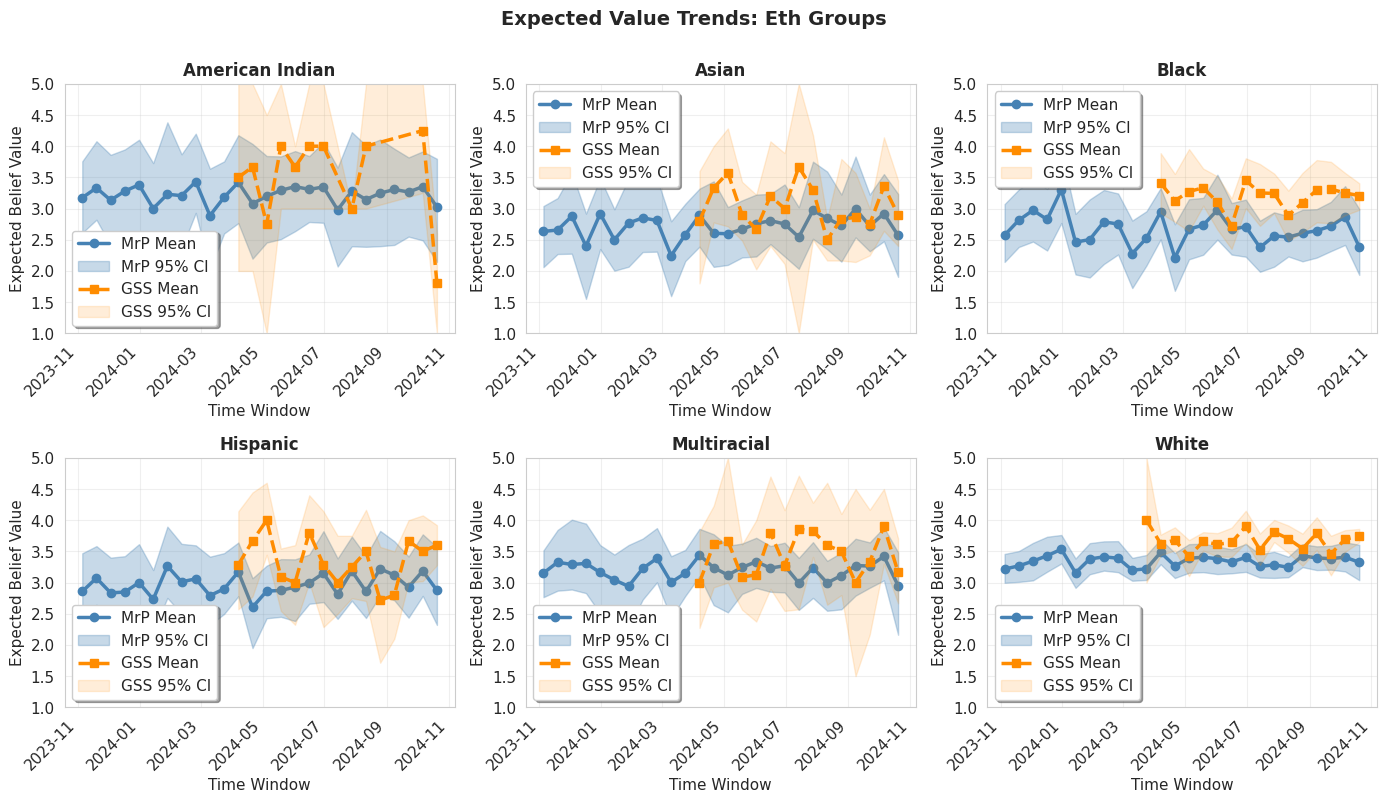

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/expected_value_trends_education.png


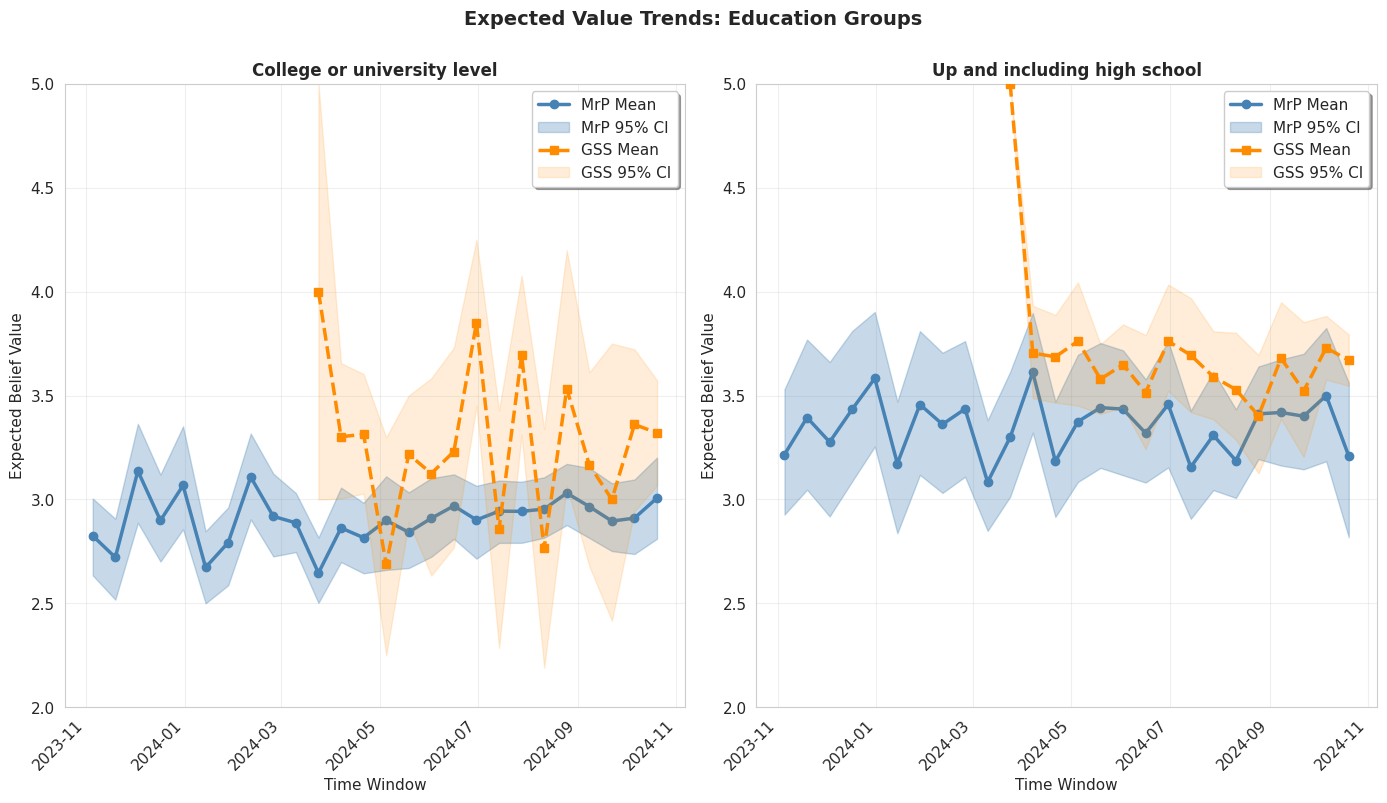


All plots saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations


In [44]:
# Create output directory for plots
plots_dir = f"{base_dir}/gss_visualizations"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots will be saved to: {plots_dir}\n")

# Plot expected value trends by sex
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='sex',
    figsize=(14, 8),
    ncols=2,
    gss_timeseries=gss_ts_sex,
    save_path=f"{plots_dir}/expected_value_trends_sex.png"
)

# Plot expected value trends by age
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='age',
    figsize=(14, 8),
    ncols=3,
    gss_timeseries=gss_ts_age,
    save_path=f"{plots_dir}/expected_value_trends_age.png"
)

# Plot expected value trends by vote
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='vote',
    figsize=(14, 8),
    ncols=3,
    gss_timeseries=gss_ts_vote,
    save_path=f"{plots_dir}/expected_value_trends_vote.png"
)

# Plot expected value trends by income (selected groups)
plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='income',
    figsize=(14, 8),
    ncols=3,\
    gss_timeseries=gss_ts_income,
    save_path=f"{plots_dir}/expected_value_trends_income.png"
)

# Plot expected value trends by ethnicity (selected groups)
plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='eth',
    figsize=(14, 8),
    ncols=3,\
    gss_timeseries=gss_ts_eth,
    save_path=f"{plots_dir}/expected_value_trends_eth.png"
)

# Plot expected value trends by education (selected groups)
plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='education',
    figsize=(14, 8),
    ncols=2,\
    gss_timeseries=gss_ts_educ,
    save_path=f"{plots_dir}/expected_value_trends_education.png"
)

print(f"\nAll plots saved to: {plots_dir}")

In [45]:
def plot_comparison_scatter_on_ax(ax, comparison_df, bootstrap_distributions, group_name, time_windows, title=""):
    """
    Plot MrP vs GSS with bootstrap-based uncertainty ellipses.
    
    This is the main orchestration function that coordinates the analysis workflow.
    
    Args:
        ax: Matplotlib axis object
        comparison_df: DataFrame with MrP predictions and metadata
        bootstrap_distributions: Dict with (group_val, window) -> list of 250 bootstrap means
        group_name: Name of demographic group ('sex', 'age', etc.)
        time_windows: DataFrame with time window definitions
        title: Plot title
    
    Returns:
        Dict with validation metrics and their confidence intervals
    """
    # Check for empty or NaN data
    if len(comparison_df) == 0 or comparison_df[['mrp_mean', 'gss_mean']].isna().all().any():
        ax.text(0.5, 0.5, 'No valid data', ha='center', va='center', transform=ax.transAxes)
        return None
    
    # Parameters
    ma_window = 3
    n_bootstrap = len(next(iter(bootstrap_distributions.values())))
    
    # Step 1: Get unique groups from comparison data
    comparison_plot_temp = comparison_df[comparison_df['demographic'] == group_name].copy()
    unique_groups = sorted(comparison_plot_temp['group'].unique())
    
    # Step 2: Apply moving average to bootstrap distributions
    ma_bootstrap_distributions = apply_moving_average_to_bootstrap(
        bootstrap_distributions, unique_groups, ma_window, n_bootstrap
    )
    
    # Step 3: Calculate confidence intervals
    comparison_plot = calculate_ma_confidence_intervals(
        comparison_df, ma_bootstrap_distributions, group_name
    )
    
    if len(comparison_plot) == 0:
        ax.text(0.5, 0.5, 'Insufficient data for moving average', ha='center', va='center', transform=ax.transAxes)
        return None
    
    # Step 4: Calculate validation metrics
    metrics = calculate_bootstrap_validation_metrics(
        comparison_plot, ma_bootstrap_distributions, n_bootstrap
    )
    
    # Step 5: Create visualization
    total_gss_samples = sum(len(v) for v in bootstrap_distributions.values())
    plot_scatter_with_uncertainty_ellipses(
        ax, comparison_plot, metrics, bootstrap_distributions, ma_window, total_gss_samples
    )
    
    # Set title
    ax.set_title(title, fontsize=12, fontweight='bold')
    
    # Return metrics with datapoint count
    return {**metrics, 'n': len(comparison_plot)}

In [46]:
def prepare_comparison_data(base_dir, belief_col, group_name, gss_timeseries):
    """
    Merge MrP predictions with GSS time series data for comparison.
    
    Parameters:
    - base_dir: Base directory containing MrP predictions
    - belief_col: Belief column name
    - group_name: Demographic group name ('sex', 'age', 'income', 'vote')
    - gss_timeseries: GSS time series DataFrame from prepare_gss_bootstrap_data
    
    Returns:
    - DataFrame with merged MrP and GSS data
    """
    # Load MrP predictions from each time window
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                           for d in time_window_dirs])
    
    all_preds = []
    for window in time_windows:
        pred_file = f"{base_dir}/{belief_col}_{window}_stan_output/group_{group_name}_predictions.csv"
        if os.path.exists(pred_file):
            preds = pd.read_csv(pred_file)
            preds['time_window_start'] = window
            all_preds.append(preds)
    
    if not all_preds:
        return pd.DataFrame()
    
    # Combine all MrP predictions
    mrp_data = pd.concat(all_preds, ignore_index=True)
    
    # Determine group column name in MrP data
    group_col = f"{group_name}_idx" if f"{group_name}_idx" in mrp_data.columns else \
                ('state_simple' if group_name == 'state' and 'state_simple' in mrp_data.columns else group_name)
    
    if group_col not in mrp_data.columns:
        print(f"Warning: Group column {group_col} not found in MrP data")
        return pd.DataFrame()
    
    # Apply labels to MrP data for matching
    mrp_data = apply_labels(mrp_data, group_col)
    
    # Prepare GSS data (already has labels applied)
    gss_data = gss_timeseries.copy()
    
    # Merge MrP and GSS data
    comparison = mrp_data.merge(
        gss_data,
        left_on=[group_col, 'time_window_start'],
        right_on=[group_name, 'time_window_start'],
        how='inner',
        suffixes=('_mrp', '_gss')
    )
    
    if len(comparison) == 0:
        return pd.DataFrame()
    
    # Rename columns for clarity (but keep the original index column)
    comparison = comparison.rename(columns={
        'pred_mean': 'mrp_mean',
        'mean': 'gss_mean'
    })
    
    # Create 'group' column from the group_col (but don't rename the original)
    comparison['group'] = comparison[group_col]
    
    # Add demographic column
    comparison['demographic'] = group_name
    
    # Select relevant columns - include the original index column for subcategory plotting
    cols_to_keep = ['demographic', 'group', 'time_window_start', 
                    'mrp_mean', 'pred_lower_68', 'pred_upper_68', 'pred_lower_95', 'pred_upper_95',
                    'gss_mean', 'lower_68', 'upper_68', 'lower_95', 'upper_95', 'n', 'sd']
    
    # Also keep the original index column (e.g., sex_idx, age_idx) for subcategory grouping
    if group_col in comparison.columns:
        cols_to_keep.append(group_col)
    
    # Keep only columns that exist
    cols_to_keep = [col for col in cols_to_keep if col in comparison.columns]
    comparison = comparison[cols_to_keep]
    
    return comparison

In [47]:
# Refactored helper functions for cleaner code

def apply_moving_average_to_bootstrap(bootstrap_distributions, unique_groups, ma_window=3, n_bootstrap=250):
    """
    Apply moving average to bootstrap distributions.
    
    Args:
        bootstrap_distributions: Dict with (group_val, window) -> list of bootstrap means
        unique_groups: List of unique group values
        ma_window: Size of moving average window (default: 3)
        n_bootstrap: Number of bootstrap iterations (default: 250)
    
    Returns:
        Dict with (group_val, window_string) -> list of MA bootstrap means
    """
    from collections import defaultdict
    
    ma_bootstrap_distributions = defaultdict(list)
    
    for group_val in unique_groups:
        # Get windows for this group
        group_windows = sorted([w for (g, w) in bootstrap_distributions.keys() if g == group_val])
        
        if len(group_windows) >= ma_window:
            # For each bootstrap iteration, apply MA to time series
            for boot_iter in range(n_bootstrap):
                # Get the bootstrap means for this iteration across windows
                bootstrap_means = []
                for window in group_windows:
                    if (group_val, window) in bootstrap_distributions:
                        bootstrap_means.append(bootstrap_distributions[(group_val, window)][boot_iter])
                
                # Apply MA
                ma_means = np.convolve(bootstrap_means, np.ones(ma_window)/ma_window, mode='valid')
                
                # Store MA means with window string as key
                for ma_idx, ma_mean in enumerate(ma_means):
                    centered_window_idx = ma_idx + (ma_window - 1) // 2
                    centered_window = group_windows[centered_window_idx]
                    key = (group_val, centered_window)
                    ma_bootstrap_distributions[key].append(ma_mean)
    
    return ma_bootstrap_distributions


def calculate_ma_confidence_intervals(comparison_df, ma_bootstrap_distributions, group_name):
    """
    Calculate bootstrap-based confidence intervals for moving average.
    
    Args:
        comparison_df: DataFrame with comparison data
        ma_bootstrap_distributions: Dict with (group_val, window) -> list of MA bootstrap means
        group_name: Name of demographic group
    
    Returns:
        DataFrame with MA means and 68% CIs
    """
    comparison_plot = comparison_df[comparison_df['demographic'] == group_name].copy()
    
    ci_data = []
    for _, row in comparison_plot.iterrows():
        group_val = row['group']
        window = row['time_window_start']
        
        key = (group_val, window)
        if key in ma_bootstrap_distributions:
            bootstrap_means = ma_bootstrap_distributions[key]
            ci_data.append({
                'group': group_val,
                'time_window_start': row['time_window_start'],
                'gss_ma_mean': np.mean(bootstrap_means),
                'gss_ma_lower_68': np.percentile(bootstrap_means, 16),
                'gss_ma_upper_68': np.percentile(bootstrap_means, 84)
            })
    
    ci_df = pd.DataFrame(ci_data)
    comparison_plot = comparison_plot.merge(ci_df, on=['group', 'time_window_start'], how='left')
    
    # Filter to only rows with bootstrap CI data
    comparison_plot = comparison_plot.dropna(subset=['gss_ma_lower_68', 'gss_ma_upper_68'])
    
    return comparison_plot


def calculate_bootstrap_validation_metrics(comparison_plot, ma_bootstrap_distributions, n_bootstrap=250):
    """
    Calculate validation metrics with bootstrap confidence intervals.
    
    Args:
        comparison_plot: DataFrame with comparison data
        ma_bootstrap_distributions: Dict with (group_val, window) -> list of MA bootstrap means
        n_bootstrap: Number of bootstrap iterations
    
    Returns:
        Dict with metrics (mean and 95% CI for bias, RMSE, correlation, coverage)
    """
    from scipy.stats import spearmanr
    
    bootstrap_bias = []
    bootstrap_rmse = []
    bootstrap_corr = []
    bootstrap_coverage = []
    
    # For each bootstrap iteration, calculate metrics
    for boot_idx in range(n_bootstrap):
        iter_ma_means = []
        iter_mrp_means = []
        iter_mrp_lower = []
        iter_mrp_upper = []
        
        for _, row in comparison_plot.iterrows():
            group_val = row['group']
            window = row['time_window_start']
            key = (group_val, window)
            
            if key in ma_bootstrap_distributions:
                iter_ma_means.append(ma_bootstrap_distributions[key][boot_idx])
                iter_mrp_means.append(row['mrp_mean'])
                iter_mrp_lower.append(row['pred_lower_95'])
                iter_mrp_upper.append(row['pred_upper_95'])
        
        if len(iter_ma_means) > 0:
            mrp_arr = np.array(iter_mrp_means)
            ma_arr = np.array(iter_ma_means)
            mrp_lower_arr = np.array(iter_mrp_lower)
            mrp_upper_arr = np.array(iter_mrp_upper)
            
            # Calculate metrics for this iteration
            bootstrap_bias.append(np.mean(mrp_arr - ma_arr))
            bootstrap_rmse.append(np.sqrt(np.mean((mrp_arr - ma_arr)**2)))
            
            # Calculate correlation for this iteration
            if len(ma_arr) > 1:
                corr, _ = spearmanr(mrp_arr, ma_arr)
                bootstrap_corr.append(corr)
            
            # Coverage
            coverage = np.mean((ma_arr >= mrp_lower_arr) & (ma_arr <= mrp_upper_arr))
            bootstrap_coverage.append(coverage)
    
    # Helper function to calculate mean and 95% CI
    def get_mean_ci(values):
        mean_val = np.mean(values)
        ci_lower = np.percentile(values, 2.5)
        ci_upper = np.percentile(values, 97.5)
        return mean_val, ci_lower, ci_upper
    
    # Calculate final metrics with CIs
    bias_mean, bias_ci_lower, bias_ci_upper = get_mean_ci(bootstrap_bias)
    rmse_mean, rmse_ci_lower, rmse_ci_upper = get_mean_ci(bootstrap_rmse)
    corr_mean, corr_ci_lower, corr_ci_upper = get_mean_ci(bootstrap_corr)
    coverage_mean, coverage_ci_lower, coverage_ci_upper = get_mean_ci(bootstrap_coverage)
    
    return {
        'bias_mean': bias_mean, 'bias_ci': (bias_ci_lower, bias_ci_upper),
        'rmse_mean': rmse_mean, 'rmse_ci': (rmse_ci_lower, rmse_ci_upper),
        'corr_mean': corr_mean, 'corr_ci': (corr_ci_lower, corr_ci_upper),
        'coverage_mean': coverage_mean, 'coverage_ci': (coverage_ci_lower, coverage_ci_upper)
    }


def plot_scatter_with_uncertainty_ellipses(ax, comparison_plot, metrics, bootstrap_distributions, 
                                           ma_window=3, total_gss_samples=0):
    """
    Create scatter plot with uncertainty ellipses and metrics annotation.
    
    Args:
        ax: Matplotlib axis object
        comparison_plot: DataFrame with comparison data including CIs
        metrics: Dict with validation metrics
        bootstrap_distributions: Original bootstrap distributions (for counting samples)
        ma_window: Moving average window size
        total_gss_samples: Total GSS sample count
    """
    from matplotlib.patches import Ellipse, Patch
    
    # Get data range with padding
    all_vals = np.concatenate([comparison_plot['mrp_mean'].values, comparison_plot['gss_ma_mean'].values])
    val_min, val_max = all_vals.min(), all_vals.max()
    val_range = val_max - val_min
    padding = val_range * 0.15
    axis_min = val_min - padding
    axis_max = val_max + padding
    
    # Add uncertainty ellipses (68% CI)
    ellipse_added = False
    for _, row in comparison_plot.iterrows():
        mrp_mean = row['mrp_mean']
        gss_mean = row['gss_ma_mean']
        
        mrp_lower = row.get('pred_lower_68')
        mrp_upper = row.get('pred_upper_68')
        gss_lower = row['gss_ma_lower_68']
        gss_upper = row['gss_ma_upper_68']
        
        if pd.isna(mrp_lower) or pd.isna(mrp_upper) or pd.isna(gss_lower) or pd.isna(gss_upper):
            continue
        
        width = mrp_upper - mrp_lower
        height = gss_upper - gss_lower
        
        ellipse = Ellipse(
            (mrp_mean, gss_mean), width=width, height=height,
            alpha=0.30, facecolor='#B0B0B0', edgecolor='#B0B0B0', linewidth=0.5
        )
        ax.add_patch(ellipse)
        ellipse_added = True
    
    # Scatter plot
    ax.scatter(comparison_plot['mrp_mean'], comparison_plot['gss_ma_mean'], 
               alpha=0.7, s=60, color='steelblue', zorder=5, 
               edgecolors='darkblue', linewidth=0.5)
    
    # Reference line
    ax.plot([axis_min, axis_max], [axis_min, axis_max], 
            'k-', lw=2, label='Perfect agreement', zorder=4)
    
    # Formatting
    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])
    ax.set_xlabel('MrP Predicted Mean', fontsize=11)
    ax.set_ylabel('GSS Mean (Bootstrap MA)', fontsize=11)
    ax.grid(True, alpha=0.3)
    
    # Legend
    handles, labels = ax.get_legend_handles_labels()
    if ellipse_added and '68% CI' not in labels:
        handles.append(Patch(facecolor='#B0B0B0', alpha=0.30, edgecolor='#B0B0B0', label='68% CI'))
    ax.legend(handles=handles, fontsize=9, loc='upper left')
    
    # Metrics text box
    textstr = (f'Bias: {metrics["bias_mean"]:.3f} ({metrics["bias_ci"][0]:.3f}, {metrics["bias_ci"][1]:.3f})\n'
               f'RMSE: {metrics["rmse_mean"]:.3f} ({metrics["rmse_ci"][0]:.3f}, {metrics["rmse_ci"][1]:.3f})\n'
               f'Corr: {metrics["corr_mean"]:.3f} ({metrics["corr_ci"][0]:.3f}, {metrics["corr_ci"][1]:.3f})\n'
               f'95% Coverage: {metrics["coverage_mean"]:.2f} ({metrics["coverage_ci"][0]:.2f}, {metrics["coverage_ci"][1]:.2f})\n'
               f'N: {len(comparison_plot)}, MA: {ma_window}')
    ax.text(0.95, 0.05, textstr, transform=ax.transAxes, fontsize=9,
            verticalalignment='bottom', horizontalalignment='right', 
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

print("Helper functions loaded successfully!")
print("  - apply_moving_average_to_bootstrap()")
print("  - calculate_ma_confidence_intervals()")
print("  - calculate_bootstrap_validation_metrics()")
print("  - plot_scatter_with_uncertainty_ellipses()")

Helper functions loaded successfully!
  - apply_moving_average_to_bootstrap()
  - calculate_ma_confidence_intervals()
  - calculate_bootstrap_validation_metrics()
  - plot_scatter_with_uncertainty_ellipses()


Comparison: MrP Predictions vs GSS Data

--- SEX ---
 Plotted 32 datapoints
  Bias: -0.295, RMSE: 0.355, Corr: 0.036

--- AGE ---
 Plotted 92 datapoints
  Bias: -0.292, RMSE: 0.388, Corr: 0.696

--- INCOME ---
 Plotted 78 datapoints
  Bias: -0.278, RMSE: 0.360, Corr: 0.369

--- VOTE ---
 Plotted 32 datapoints
  Bias: -0.268, RMSE: 0.679, Corr: 0.766

--- ETH ---
 Plotted 87 datapoints
  Bias: -0.348, RMSE: 0.486, Corr: 0.526

--- EDUCATION ---
 Plotted 32 datapoints
  Bias: -0.306, RMSE: 0.356, Corr: 0.727

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_all_demographics.png


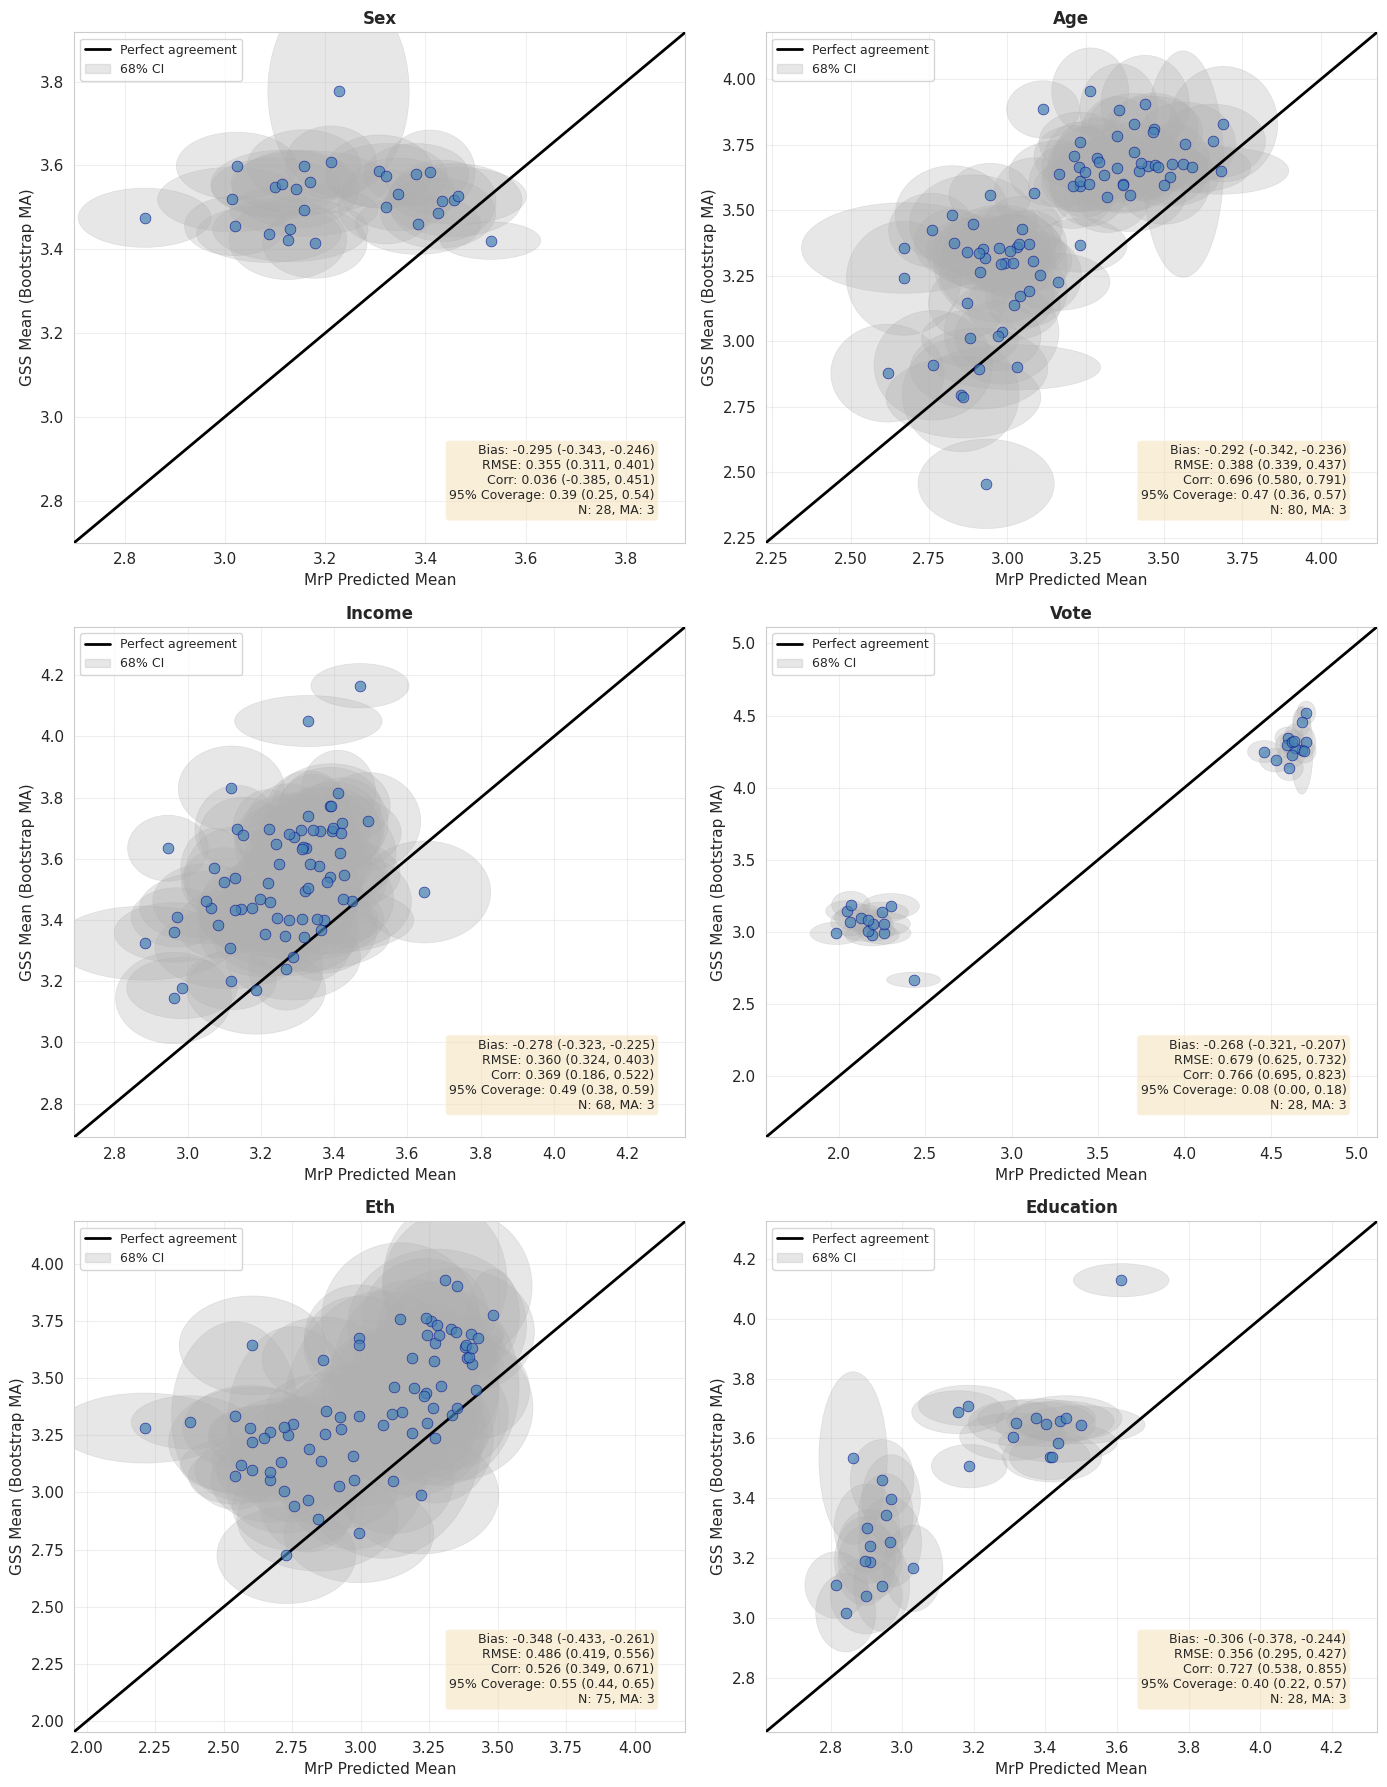

In [48]:
# Overall comparison per demographic across all time windows
from scipy.stats import spearmanr

print("=" * 60)
print("Comparison: MrP Predictions vs GSS Data")
print("=" * 60)

# Create a 3x2 subplot grid
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.flatten()

all_metrics = {}
group_list = [('sex', gss_ts_sex, gss_boot_sex), ('age', gss_ts_age, gss_boot_age), 
              ('income', gss_ts_income, gss_boot_income), ('vote', gss_ts_vote, gss_boot_vote), ('eth', gss_ts_eth, gss_boot_eth),('education', gss_ts_educ, gss_boot_educ)]

# Create time_windows DataFrame for the function
time_windows_df = pd.DataFrame({'start_year': time_windows})

for idx, (group_name, gss_ts, gss_boot) in enumerate(group_list):
    print(f"\n--- {group_name.upper()} ---")
    try:
        # Prepare comparison data (merges MrP predictions with GSS data)
        comparison = prepare_comparison_data(base_dir, belief_col, group_name, gss_ts)
        if len(comparison) > 0:
            # Plot using new function with bootstrap distributions
            metrics = plot_comparison_scatter_on_ax(
                axes[idx],
                comparison,
                gss_boot,  # Pass bootstrap distributions
                group_name,
                time_windows_df,
                title=f'{group_name.capitalize()}'
            )
            all_metrics[group_name] = metrics
            print(f" Plotted {len(comparison)} datapoints")
            if metrics:
                print(f"  Bias: {metrics['bias_mean']:.3f}, RMSE: {metrics['rmse_mean']:.3f}, Corr: {metrics['corr_mean']:.3f}")
        else:
            axes[idx].text(0.5, 0.5, f'No data for {group_name}', ha='center', va='center', transform=axes[idx].transAxes)
            print(f"  No matching data")
    except Exception as e:
        axes[idx].text(0.5, 0.5, f'Error: {str(e)[:50]}', ha='center', va='center', transform=axes[idx].transAxes, fontsize=9)
        print(f"  Error: {str(e)}")

plt.tight_layout()
plt.savefig(f"{plots_dir}/comparison_all_demographics.png", dpi=300, bbox_inches='tight')
print(f"\nPlot saved to: {plots_dir}/comparison_all_demographics.png")
plt.show()


Combined Comparison: All Groups & Time Windows (with Bootstrap MA)
 sex: 28 datapoints
 age: 80 datapoints
 income: 68 datapoints
 vote: 28 datapoints
 eth: 75 datapoints
 education: 28 datapoints

Total combined datapoints: 307

 Combined comparison plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_all_combined.png
  Overall Bias: -0.3018 (-0.3334, -0.2679)
  Overall RMSE: 0.4375 (0.4101, 0.4649)
  Overall Corr: 0.679 (0.616, 0.735)
  Total datapoints: 307


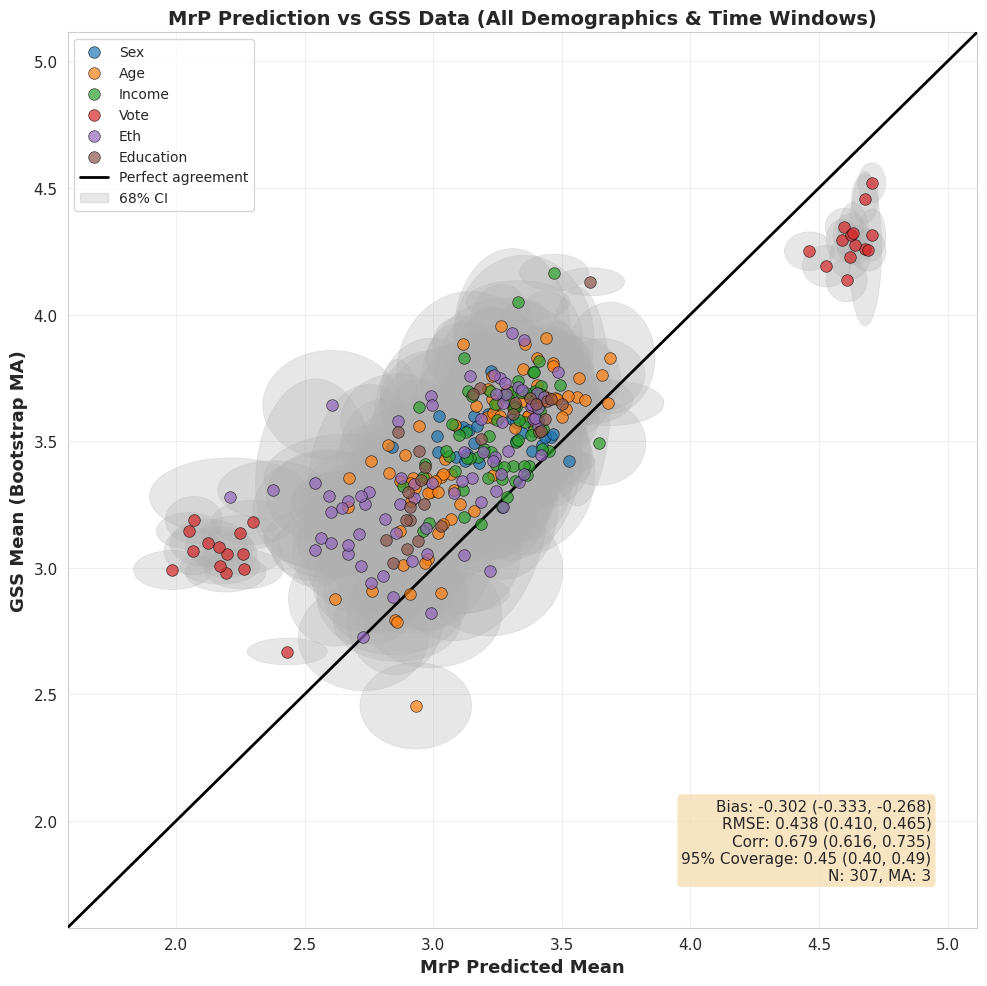

In [49]:
# Combined comparison: All groups and time windows on single y=x plot
from matplotlib.patches import Ellipse, Patch
from scipy.stats import spearmanr

print("\n" + "=" * 60)
print("Combined Comparison: All Groups & Time Windows (with Bootstrap MA)")
print("=" * 60)

# Prepare comparison data and apply moving average for all groups
all_comparison_with_ma = []
all_ma_distributions = {}
group_colors = {'sex': '#1f77b4', 'age': '#ff7f0e', 'income': '#2ca02c', 'vote': '#d62728', 'eth': '#9467bd', 'education': '#8c564b'}

ma_window = 3
n_bootstrap = 250

for group_name, gss_ts, gss_boot in [
                                      ('sex', gss_ts_sex, gss_boot_sex), 
                                      ('age', gss_ts_age, gss_boot_age), 
                                      ('income', gss_ts_income, gss_boot_income), 
                                      ('vote', gss_ts_vote, gss_boot_vote),
                                      ('eth', gss_ts_eth, gss_boot_eth),
                                      ('education', gss_ts_educ, gss_boot_educ)
                                    ]:
    try:
        # Prepare comparison data
        comparison = prepare_comparison_data(base_dir, belief_col, group_name, gss_ts)
        if len(comparison) == 0:
            print(f"  ✗ {group_name}: No matching data")
            continue
        
        # Get unique groups
        comparison['demographic'] = group_name
        unique_groups = sorted(comparison['group'].unique())
        
        # Apply moving average to bootstrap distributions
        ma_bootstrap_distributions = apply_moving_average_to_bootstrap(
            gss_boot, unique_groups, ma_window, n_bootstrap
        )
        
        # Calculate MA confidence intervals
        comparison_with_ma = calculate_ma_confidence_intervals(
            comparison, ma_bootstrap_distributions, group_name
        )
        
        if len(comparison_with_ma) > 0:
            comparison_with_ma['demographic'] = group_name
            all_comparison_with_ma.append(comparison_with_ma)
            # Store MA distributions for this group
            for key, values in ma_bootstrap_distributions.items():
                all_ma_distributions[(group_name, key[0], key[1])] = values
            print(f" {group_name}: {len(comparison_with_ma)} datapoints")
        else:
            print(f" {group_name}: Insufficient data for MA")
    except Exception as e:
        print(f"  Warning: Could not process {group_name}: {str(e)}")

# Combine all data
if len(all_comparison_with_ma) > 0:
    combined_data = pd.concat(all_comparison_with_ma, ignore_index=True)
    combined_data = combined_data.dropna(subset=['mrp_mean', 'gss_ma_mean'])
    
    print(f"\nTotal combined datapoints: {len(combined_data)}")
    
    # Create single plot
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Get data range with padding
    all_vals = np.concatenate([combined_data['mrp_mean'].values, combined_data['gss_ma_mean'].values])
    val_min, val_max = all_vals.min(), all_vals.max()
    val_range = val_max - val_min
    padding = val_range * 0.15
    axis_min = val_min - padding
    axis_max = val_max + padding
    
    # Add uncertainty ellipses (68% CI)
    ellipse_added = False
    for _, row in combined_data.iterrows():
        mrp_mean = row['mrp_mean']
        gss_mean = row['gss_ma_mean']
        
        mrp_lower = row.get('pred_lower_68')
        mrp_upper = row.get('pred_upper_68')
        gss_lower = row['gss_ma_lower_68']
        gss_upper = row['gss_ma_upper_68']
        
        if pd.isna(mrp_lower) or pd.isna(mrp_upper) or pd.isna(gss_lower) or pd.isna(gss_upper):
            continue
        
        width = mrp_upper - mrp_lower
        height = gss_upper - gss_lower
        
        ellipse = Ellipse(
            (mrp_mean, gss_mean), width=width, height=height,
            alpha=0.30, facecolor='#B0B0B0', edgecolor='#B0B0B0', linewidth=0.5
        )
        ax.add_patch(ellipse)
        ellipse_added = True
    
    # Plot each group with different color
    group_handles = []
    for group_name in combined_data['demographic'].unique():
        group_data = combined_data[combined_data['demographic'] == group_name]
        scatter = ax.scatter(
            group_data['mrp_mean'], group_data['gss_ma_mean'], 
            alpha=0.7, s=70, label=group_name.capitalize(),
            color=group_colors[group_name], edgecolors='black', linewidth=0.5, zorder=5
        )
        group_handles.append(scatter)
    
    # y=x reference line
    line = ax.plot([axis_min, axis_max], [axis_min, axis_max], 
                   'k-', lw=2, label='Perfect agreement', zorder=4)[0]
    
    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])
    ax.set_xlabel('MrP Predicted Mean', fontsize=13, fontweight='bold')
    ax.set_ylabel('GSS Mean (Bootstrap MA)', fontsize=13, fontweight='bold')
    ax.set_title('MrP Prediction vs GSS Data (All Demographics & Time Windows)', 
                 fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Combine all legend handles together
    all_legend_handles = group_handles + [line]
    if ellipse_added:
        ci_patch = Patch(facecolor='#B0B0B0', alpha=0.30, edgecolor='#B0B0B0', label='68% CI')
        all_legend_handles.append(ci_patch)
    
    # Single combined legend at top left
    ax.legend(handles=all_legend_handles, fontsize=10, loc='upper left')
    
    # Prepare combined MA distributions in format expected by helper function
    # Convert from (demo, group_val, window) -> list to (group_val, window) -> list
    # by creating a temporary combined key that includes demographic info
    combined_ma_distributions = {}
    for (demo, group_val, window), values in all_ma_distributions.items():
        # Create unique key combining demo and group for metrics calculation
        combined_key = (f"{demo}_{group_val}", window)
        combined_ma_distributions[combined_key] = values
    
    # Prepare combined_data with matching group format
    combined_data_for_metrics = combined_data.copy()
    combined_data_for_metrics['group'] = combined_data_for_metrics['demographic'] + '_' + combined_data_for_metrics['group'].astype(str)
    
    # Calculate bootstrap-based metrics using helper function
    metrics = calculate_bootstrap_validation_metrics(
        combined_data_for_metrics, 
        combined_ma_distributions, 
        n_bootstrap
    )
    
    bias_mean = metrics['bias_mean']
    bias_ci_lower, bias_ci_upper = metrics['bias_ci']
    rmse_mean = metrics['rmse_mean']
    rmse_ci_lower, rmse_ci_upper = metrics['rmse_ci']
    corr_mean = metrics['corr_mean']
    corr_ci_lower, corr_ci_upper = metrics['corr_ci']
    coverage_mean = metrics['coverage_mean']
    coverage_ci_lower, coverage_ci_upper = metrics['coverage_ci']
    
    # Add metrics text box
    textstr = (f'Bias: {bias_mean:.3f} ({bias_ci_lower:.3f}, {bias_ci_upper:.3f})\n'
               f'RMSE: {rmse_mean:.3f} ({rmse_ci_lower:.3f}, {rmse_ci_upper:.3f})\n'
               f'Corr: {corr_mean:.3f} ({corr_ci_lower:.3f}, {corr_ci_upper:.3f})\n'
               f'95% Coverage: {coverage_mean:.2f} ({coverage_ci_lower:.2f}, {coverage_ci_upper:.2f})\n'
               f'N: {len(combined_data)}, MA: {ma_window}')
    
    ax.text(0.95, 0.05, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='bottom', horizontalalignment='right', 
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.tight_layout()
    plt.savefig(f"{plots_dir}/comparison_all_combined.png", dpi=300, bbox_inches='tight')
    print(f"\n Combined comparison plot saved to: {plots_dir}/comparison_all_combined.png")
    print(f"  Overall Bias: {bias_mean:.4f} ({bias_ci_lower:.4f}, {bias_ci_upper:.4f})")
    print(f"  Overall RMSE: {rmse_mean:.4f} ({rmse_ci_lower:.4f}, {rmse_ci_upper:.4f})")
    print(f"  Overall Corr: {corr_mean:.3f} ({corr_ci_lower:.3f}, {corr_ci_upper:.3f})")
    print(f"  Total datapoints: {len(combined_data)}")
    plt.show()
else:
    print("\n No valid data after applying moving average to all groups")



Per-Group Subcategory Comparison: MrP vs GSS (with Bootstrap MA)

--- SEX ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_sex_subcategories.png


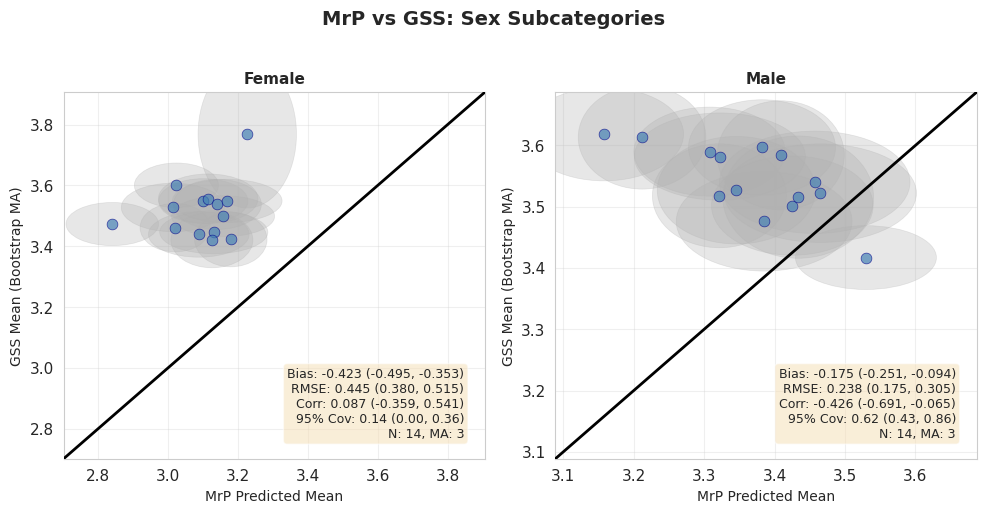


--- AGE ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_age_subcategories.png


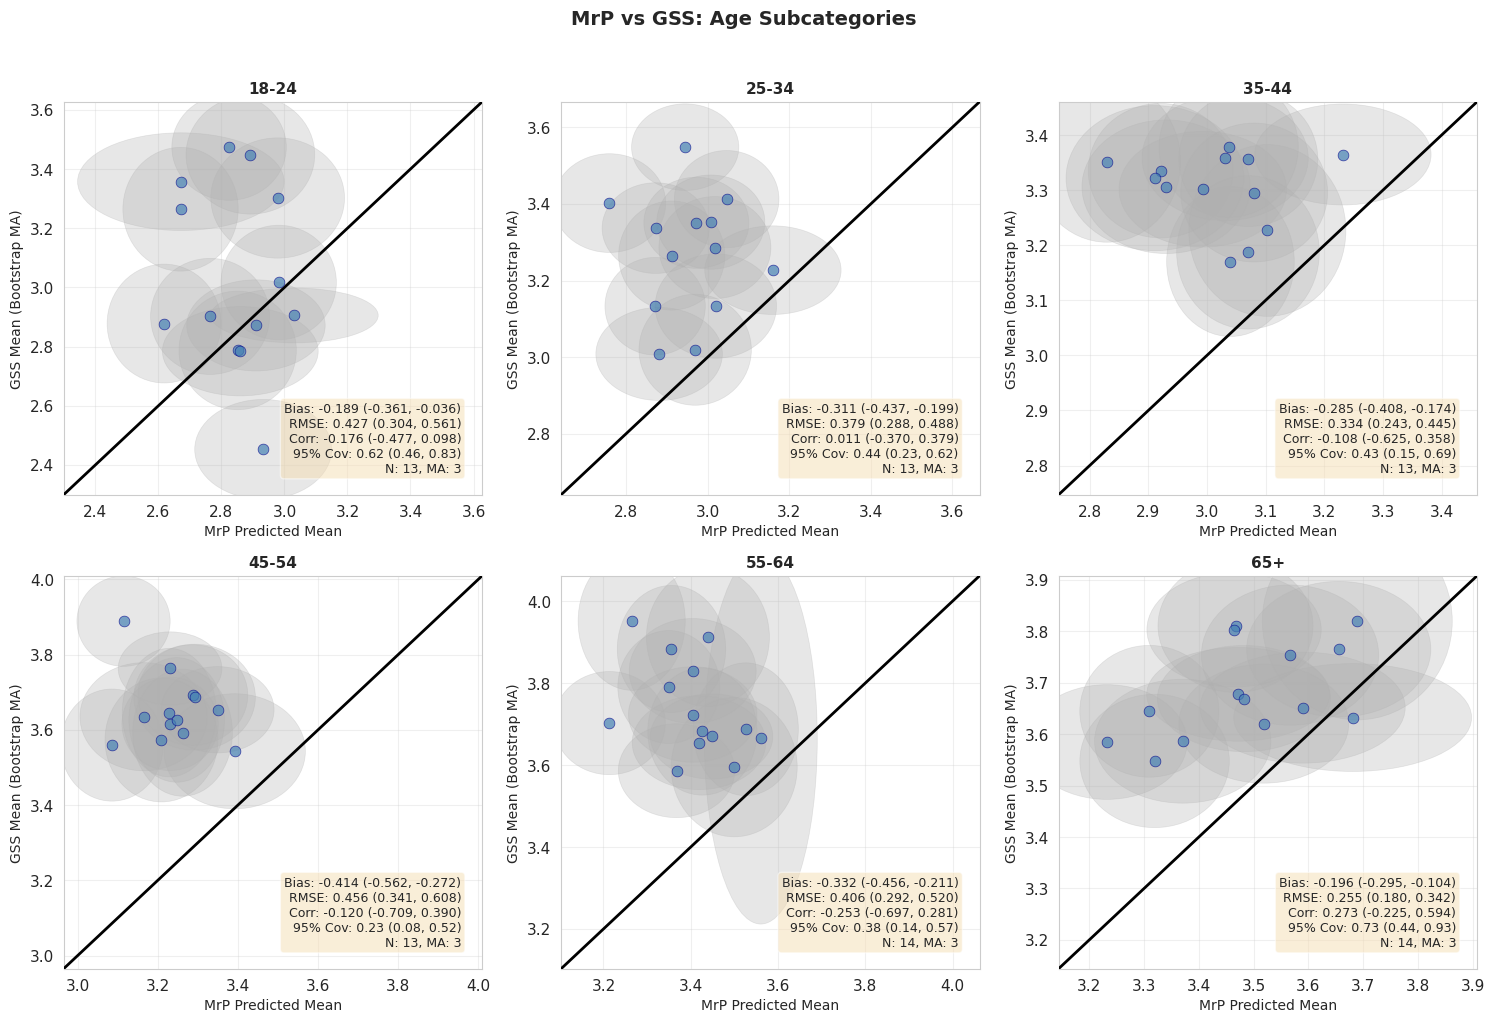


--- INCOME ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_income_subcategories.png


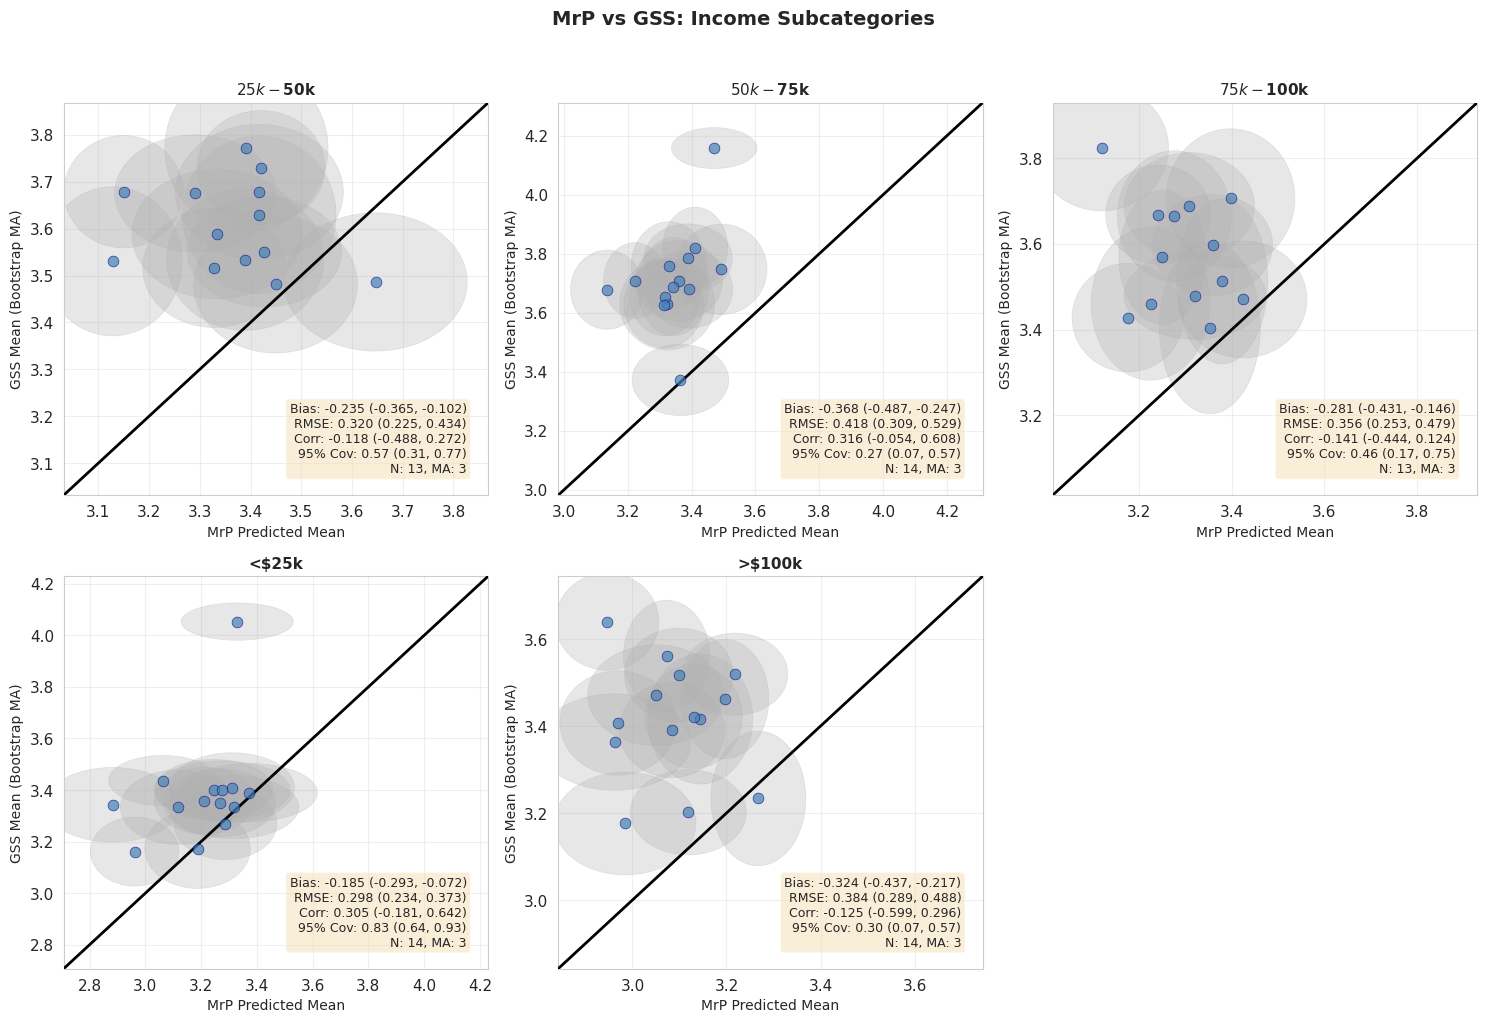


--- VOTE ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_vote_subcategories.png


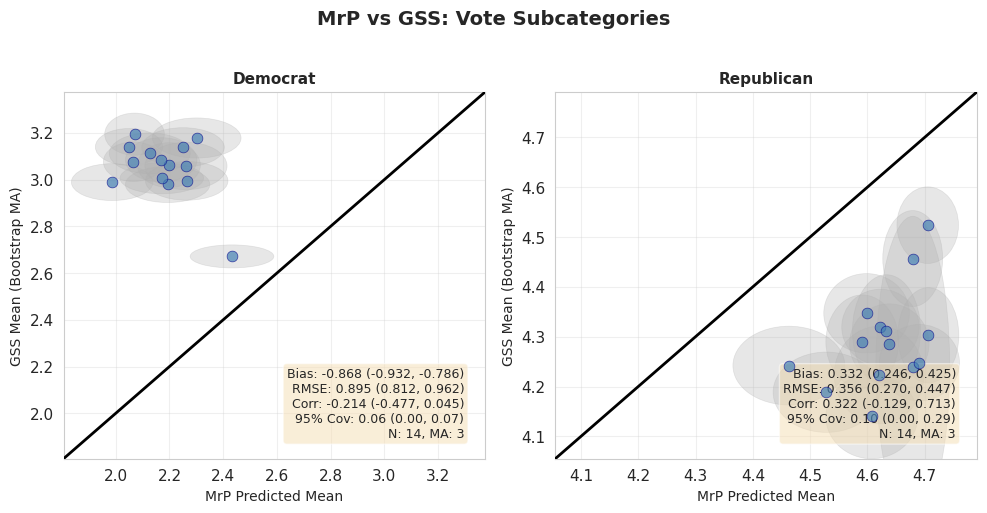


--- ETH ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_eth_subcategories.png


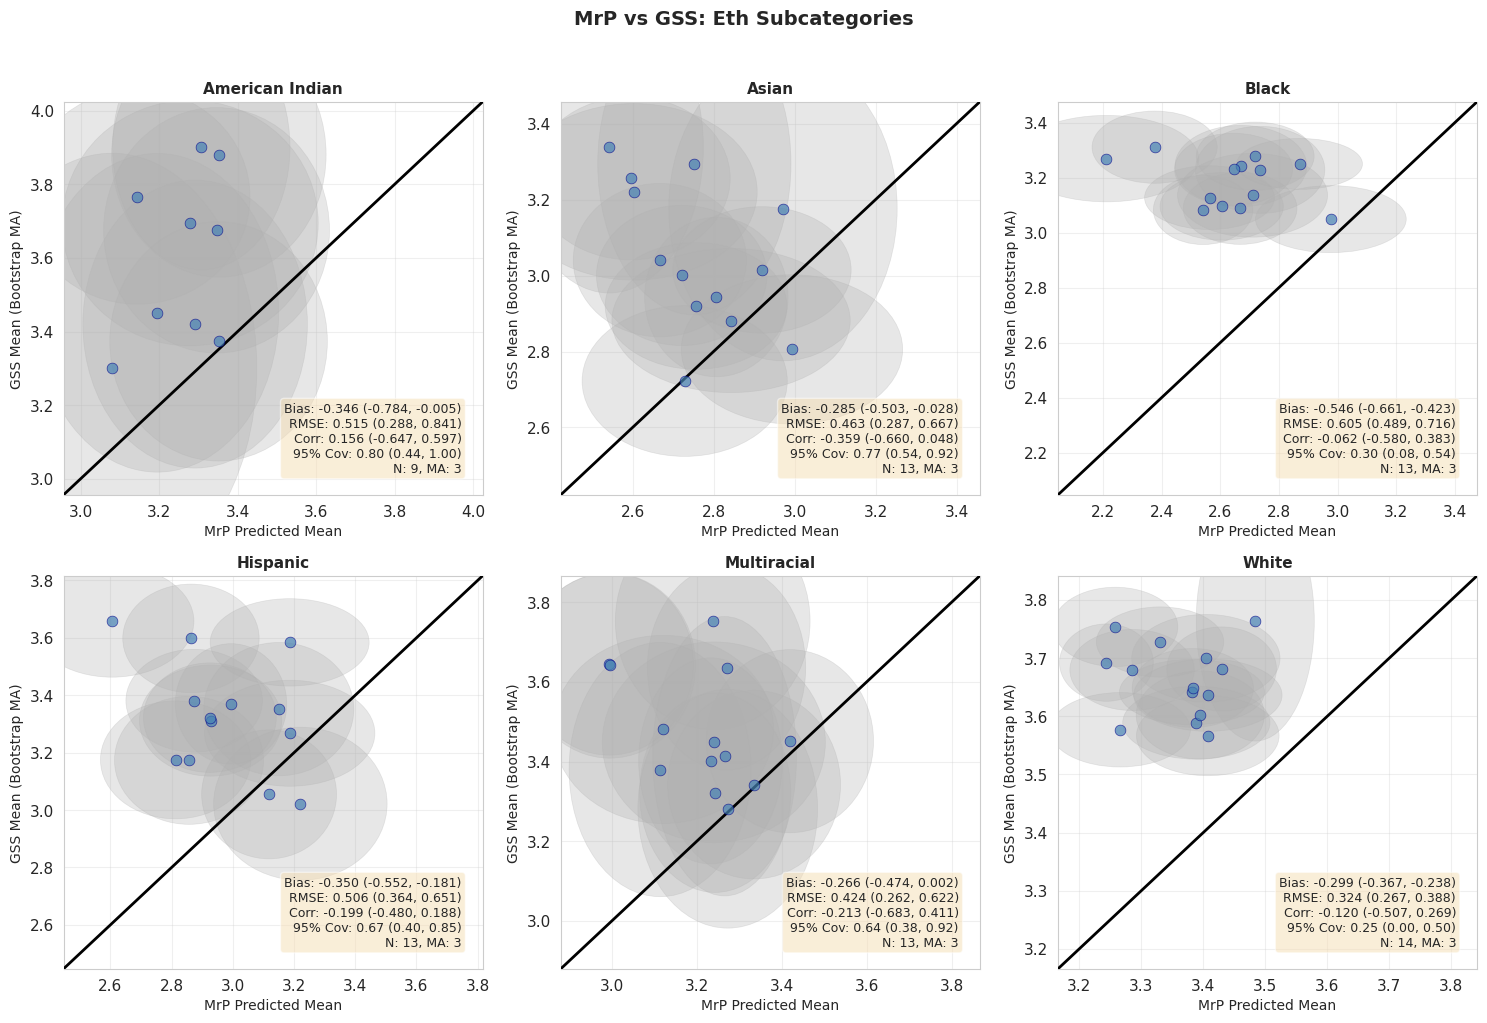


--- EDUCATION ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_education_subcategories.png


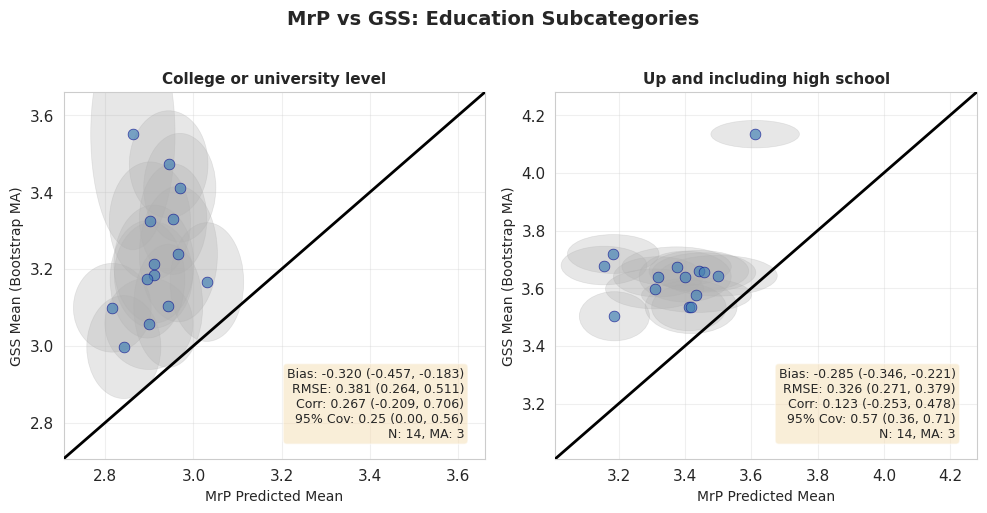

In [ ]:

# Per-group category-level comparison: y=x plots for each subcategory
print("\n" + "=" * 60)
print("Per-Group Subcategory Comparison: MrP vs GSS (with Bootstrap MA)")
print("=" * 60)

# Helper: map numeric indices to labels for subplot titles
label_maps = {k.replace('_idx', ''): v for k, v in label_mappings.items()}

ma_window = 3
n_bootstrap = 250

# Build a combined dataframe for each demographic, then plot each subcategory
for group_name, gss_ts, gss_boot in [('sex', gss_ts_sex, gss_boot_sex), 
                                      ('age', gss_ts_age, gss_boot_age), 
                                      ('income', gss_ts_income, gss_boot_income), 
                                      ('vote', gss_ts_vote, gss_boot_vote),
                                      ('eth', gss_ts_eth, gss_boot_eth),
                                      ('education', gss_ts_educ, gss_boot_educ)]:
    print(f"\n--- {group_name.upper()} ---")
    try:
        # Prepare comparison data
        comparison = prepare_comparison_data(base_dir, belief_col, group_name, gss_ts)
        if len(comparison) == 0:
            print(f"  No matching data found for {group_name}")
            continue
        
        # Identify numeric group column for subcategory grouping (do this before MA filtering)
        mrp_group_col = f"{group_name}_idx"
        if mrp_group_col not in comparison.columns:
            print(f"  Missing column {mrp_group_col} in comparison data")
            print(f"  Available columns: {comparison.columns.tolist()}")
            continue
        
        # Add demographic column (if not already present)
        if 'demographic' not in comparison.columns:
            comparison['demographic'] = group_name
        
        # Get unique groups and apply MA
        unique_groups = sorted(comparison['group'].unique())
        ma_bootstrap_distributions = apply_moving_average_to_bootstrap(
            gss_boot, unique_groups, ma_window, n_bootstrap
        )
        
        # Calculate MA confidence intervals
        comparison_with_ma = calculate_ma_confidence_intervals(
            comparison, ma_bootstrap_distributions, group_name
        )
        
        if len(comparison_with_ma) == 0:
            print(f"  Insufficient data for MA after filtering")
            continue
        
        # List subcategory ids present in data
        subgroup_ids = sorted(comparison_with_ma[mrp_group_col].dropna().unique())
        n_groups = len(subgroup_ids)
        if n_groups == 0:
            print(f"  No subcategories found for {group_name}")
            continue
        
        # Layout
        ncols = 3 if n_groups > 3 else n_groups
        nrows = int(np.ceil(n_groups / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
        axes = axes.flatten()
        
        # Label map for titles
        group_label_map = label_maps.get(group_name, {})
        
        # Count total GSS samples for this group
        total_gss_samples = sum(len(v) for (g, w) in gss_boot.keys() for v in [gss_boot[(g, w)]] if g in unique_groups)
        
        for idx, sub_id in enumerate(subgroup_ids):
            ax = axes[idx]
            sub_data = comparison_with_ma[comparison_with_ma[mrp_group_col] == sub_id].copy()
            sub_data = sub_data.dropna(subset=['mrp_mean', 'gss_ma_mean'])
            
            if len(sub_data) == 0:
                ax.text(0.5, 0.5, 'No valid data', ha='center', va='center', transform=ax.transAxes)
                ax.set_axis_off()
                continue
            
            # Calculate metrics using helper function
            metrics = calculate_bootstrap_validation_metrics(
                sub_data, ma_bootstrap_distributions, n_bootstrap
            )
            
            if metrics is None:
                ax.text(0.5, 0.5, 'Insufficient data for metrics', ha='center', va='center', transform=ax.transAxes)
                ax.set_axis_off()
                continue
            
            # Get data range with padding
            all_vals = np.concatenate([sub_data['mrp_mean'].values, sub_data['gss_ma_mean'].values])
            val_min, val_max = all_vals.min(), all_vals.max()
            val_range = val_max - val_min
            padding = val_range * 0.15 if val_range > 0 else 0.5
            axis_min = val_min - padding
            axis_max = val_max + padding
            
            # Add uncertainty ellipses (68% CI)
            ellipse_added = False
            for _, row in sub_data.iterrows():
                mrp_mean = row['mrp_mean']
                gss_mean = row['gss_ma_mean']
                
                mrp_lower = row.get('pred_lower_68')
                mrp_upper = row.get('pred_upper_68')
                gss_lower = row['gss_ma_lower_68']
                gss_upper = row['gss_ma_upper_68']
                
                if pd.isna(mrp_lower) or pd.isna(mrp_upper) or pd.isna(gss_lower) or pd.isna(gss_upper):
                    continue
                
                width = mrp_upper - mrp_lower
                height = gss_upper - gss_lower
                
                ellipse = Ellipse(
                    (mrp_mean, gss_mean), width=width, height=height,
                    alpha=0.30, facecolor='#B0B0B0', edgecolor='#B0B0B0', linewidth=0.5
                )
                ax.add_patch(ellipse)
                ellipse_added = True
            
            # Scatter plot on top
            ax.scatter(sub_data['mrp_mean'], sub_data['gss_ma_mean'], 
                      alpha=0.7, s=60, color='steelblue', zorder=5, 
                      edgecolors='darkblue', linewidth=0.5)
            ax.plot([axis_min, axis_max], [axis_min, axis_max], 'k-', lw=2, zorder=4)
            ax.set_xlim([axis_min, axis_max])
            ax.set_ylim([axis_min, axis_max])
            ax.set_xlabel('MrP Predicted Mean', fontsize=10)
            ax.set_ylabel('GSS Mean (Bootstrap MA)', fontsize=10)
            
            # Title
            label = group_label_map.get(sub_id, str(sub_id))
            ax.set_title(f"{label}", fontsize=11, fontweight='bold')
            ax.grid(True, alpha=0.3)
            
            # Metrics text with CIs
            bias_mean = metrics['bias_mean']
            bias_ci = metrics['bias_ci']
            rmse_mean = metrics['rmse_mean']
            rmse_ci = metrics['rmse_ci']
            corr_mean = metrics['corr_mean']
            corr_ci = metrics['corr_ci']
            coverage_mean = metrics['coverage_mean']
            coverage_ci = metrics['coverage_ci']
            
            textstr = (f'Bias: {bias_mean:.3f} ({bias_ci[0]:.3f}, {bias_ci[1]:.3f})\n'
                      f'RMSE: {rmse_mean:.3f} ({rmse_ci[0]:.3f}, {rmse_ci[1]:.3f})\n'
                      f'Corr: {corr_mean:.3f} ({corr_ci[0]:.3f}, {corr_ci[1]:.3f})\n'
                      f'95% Cov: {coverage_mean:.2f} ({coverage_ci[0]:.2f}, {coverage_ci[1]:.2f})\n'
                      f'N: {len(sub_data)}, MA: {ma_window}')
            ax.text(0.95, 0.05, textstr, transform=ax.transAxes, fontsize=9,
                   verticalalignment='bottom', horizontalalignment='right', 
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
        # Hide unused axes
        for j in range(n_groups, len(axes)):
            axes[j].set_axis_off()
        
        plt.suptitle(f'MrP vs GSS: {group_name.capitalize()} Subcategories', 
                    fontsize=14, fontweight='bold', y=1.02)
        plt.tight_layout()
        out_path = f"{plots_dir}/comparison_{group_name}_subcategories.png"
        plt.savefig(out_path, dpi=300, bbox_inches='tight')
        print(f"  Saved: {out_path}")
        plt.show()
    except Exception as e:
        print(f"  Error processing {group_name}: {str(e)}")




Temporal Analysis: Before vs After July 1st

Before July 1st: 150 datapoints
After July 1st: 157 datapoints

✓ Temporal comparison plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol/gss_visualizations/comparison_before_after_july.png


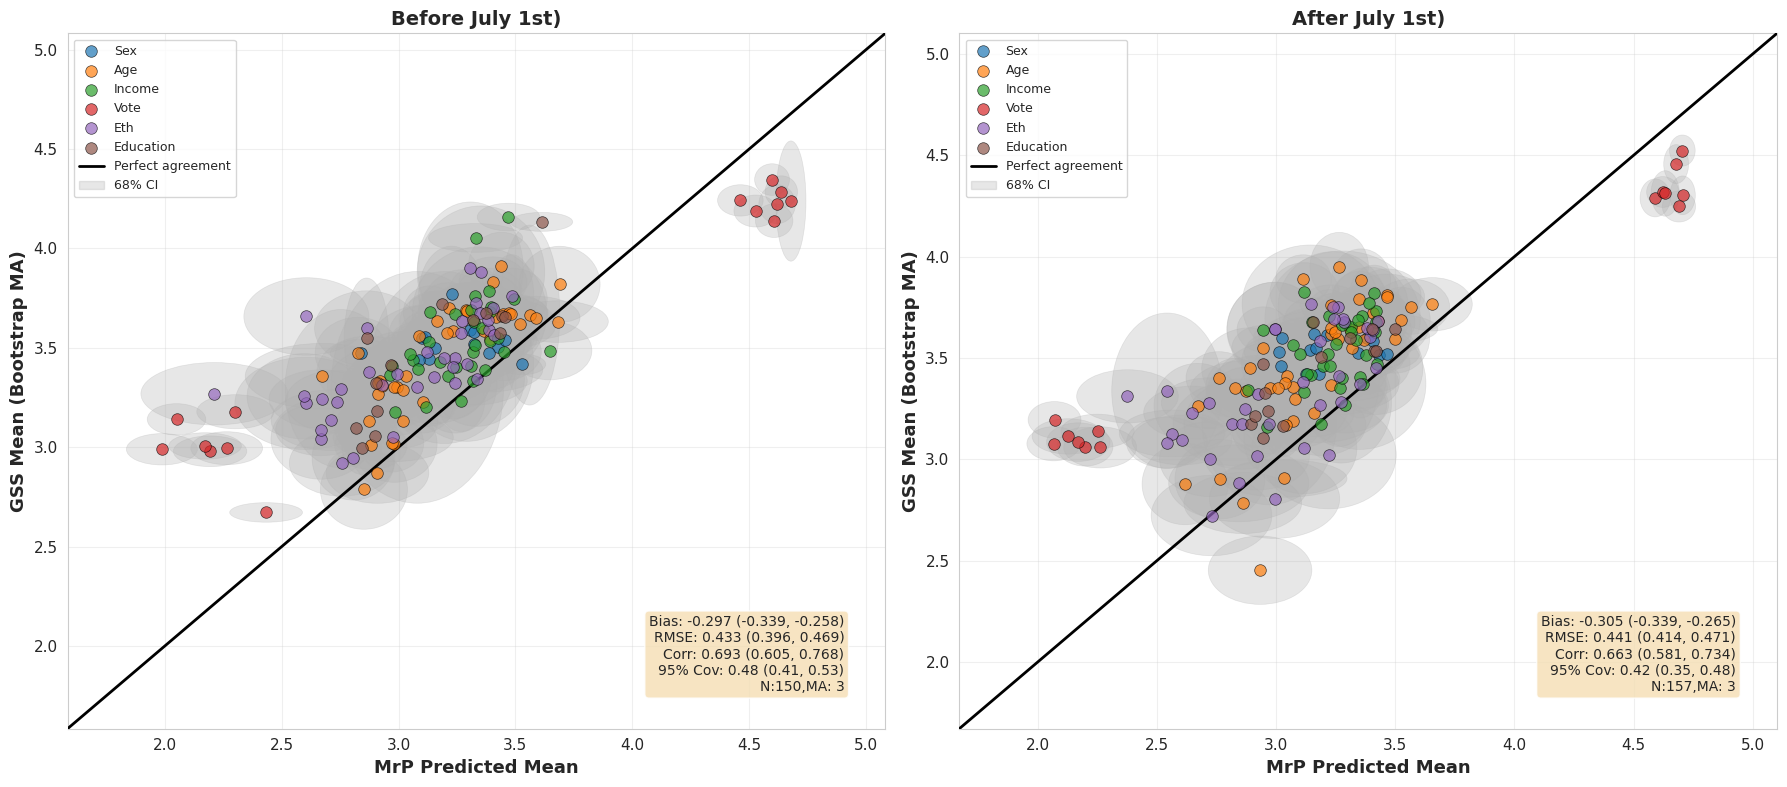


Statistical Comparison of Prediction Accuracy

BEFORE July 1st:
  Bias: -0.2968 (CI: -0.3390 to -0.2577)
  RMSE: 0.4326 (CI: 0.3958 to 0.4693)
  Correlation: 0.6927 (CI: 0.6050 to 0.7677)
  95% Coverage: 0.4776 (CI: 0.4067 to 0.5333)

 AFTER July 1st:
  Bias: -0.3051 (CI: -0.3394 to -0.2651)
  RMSE: 0.4405 (CI: 0.4144 to 0.4706)
  Correlation: 0.6631 (CI: 0.5811 to 0.7343)
  95% Coverage: 0.4170 (CI: 0.3454 to 0.4841)

DIFFERENCE (After - Before):
  Bias difference: -0.0083
  RMSE difference: +0.0079
  Correlation difference: -0.0296
  Coverage difference: -0.0606

SIGNIFICANCE (based on 95% CI overlap):
  Bias: Not significant (CIs overlap)
  RMSE: Not significant (CIs overlap)
  Correlation: Not significant (CIs overlap)
  Coverage: Not significant (CIs overlap)

2. Two-Sample T-test (comparing raw prediction errors):
  t-statistic: 0.2642
  p-value: 0.7918
  Result: Not significant (α = 0.05)

3. Mann-Whitney U Test (non-parametric):
  U-statistic: 11374.0000
  p-value: 0.6065
  Re

In [ ]:
# Compare predictions before and after July 1st
from scipy import stats

print("\n" + "=" * 60)
print("Temporal Analysis: Before vs After July 1st")
print("=" * 60)

# Ensure combined_data has datetime column
if 'time_dt' not in combined_data.columns:
    combined_data['time_dt'] = pd.to_datetime(combined_data['time_window_start'])

combined_data['time_dt'] = pd.to_datetime(combined_data['time_dt']).dt.tz_localize(None)
# Define July 1st, 2024 as the cutoff date
cutoff_date = pd.to_datetime('2024-07-01')

# Split data based on whether time_dt is before or after July 1, 2024
combined_data['period'] = combined_data['time_dt'].apply(
    lambda x: 'Before July 1, 2024' if x < cutoff_date else 'On/After July 1, 2024'
)

# Split data into two groups
data_before = combined_data[combined_data['period'] == 'Before July 1, 2024'].copy()
data_after = combined_data[combined_data['period'] == 'On/After July 1, 2024'].copy()

print(f"\nBefore July 1st: {len(data_before)} datapoints")
print(f"After July 1st: {len(data_after)} datapoints")

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Function to plot one period
def plot_period_comparison(ax, data, all_ma_dist, period_name, group_colors):
    """Plot comparison for one time period"""
    if len(data) == 0:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
        return None
    
    # Get data range with padding
    all_vals = np.concatenate([data['mrp_mean'].values, data['gss_ma_mean'].values])
    val_min, val_max = all_vals.min(), all_vals.max()
    val_range = val_max - val_min
    padding = val_range * 0.15
    axis_min = val_min - padding
    axis_max = val_max + padding
    
    # Add uncertainty ellipses (68% CI)
    ellipse_added = False
    for _, row in data.iterrows():
        mrp_mean = row['mrp_mean']
        gss_mean = row['gss_ma_mean']
        
        mrp_lower = row.get('pred_lower_68')
        mrp_upper = row.get('pred_upper_68')
        gss_lower = row['gss_ma_lower_68']
        gss_upper = row['gss_ma_upper_68']
        
        if pd.isna(mrp_lower) or pd.isna(mrp_upper) or pd.isna(gss_lower) or pd.isna(gss_upper):
            continue
        
        width = mrp_upper - mrp_lower
        height = gss_upper - gss_lower
        
        ellipse = Ellipse(
            (mrp_mean, gss_mean), width=width, height=height,
            alpha=0.30, facecolor='#B0B0B0', edgecolor='#B0B0B0', linewidth=0.5
        )
        ax.add_patch(ellipse)
        ellipse_added = True
    
    # Plot each group with different color
    group_handles = []
    for group_name in data['demographic'].unique():
        group_data = data[data['demographic'] == group_name]
        scatter = ax.scatter(
            group_data['mrp_mean'], group_data['gss_ma_mean'], 
            alpha=0.7, s=70, label=group_name.capitalize(),
            color=group_colors[group_name], edgecolors='black', linewidth=0.5, zorder=5
        )
        group_handles.append(scatter)
    
    # y=x reference line
    line = ax.plot([axis_min, axis_max], [axis_min, axis_max], 
                   'k-', lw=2, label='Perfect agreement', zorder=4)[0]
    
    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])
    ax.set_xlabel('MrP Predicted Mean', fontsize=13, fontweight='bold')
    ax.set_ylabel('GSS Mean (Bootstrap MA)', fontsize=13, fontweight='bold')
    ax.set_title(f'{period_name})', 
                 fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Combined legend
    all_legend_handles = group_handles + [line]
    if ellipse_added:
        ci_patch = Patch(facecolor='#B0B0B0', alpha=0.30, edgecolor='#B0B0B0', label='68% CI')
        all_legend_handles.append(ci_patch)
    ax.legend(handles=all_legend_handles, fontsize=9, loc='upper left')
    
    # Calculate metrics for this period using MA distributions
    period_ma_distributions = {}
    for _, row in data.iterrows():
        demo = row['demographic']
        group_val = row['group']
        window = row['time_window_start']
        key = (demo, group_val, window)
        
        if key in all_ma_dist:
            combined_key = (f"{demo}_{group_val}", window)
            period_ma_distributions[combined_key] = all_ma_dist[key]
    
    # Prepare data for metrics calculation
    data_for_metrics = data.copy()
    data_for_metrics['group'] = data_for_metrics['demographic'] + '_' + data_for_metrics['group'].astype(str)
    
    # Calculate metrics
    metrics = calculate_bootstrap_validation_metrics(
        data_for_metrics, 
        period_ma_distributions, 
        n_bootstrap
    )
    
    if metrics:
        bias_mean = metrics['bias_mean']
        bias_ci = metrics['bias_ci']
        rmse_mean = metrics['rmse_mean']
        rmse_ci = metrics['rmse_ci']
        corr_mean = metrics['corr_mean']
        corr_ci = metrics['corr_ci']
        coverage_mean = metrics['coverage_mean']
        coverage_ci = metrics['coverage_ci']
        
        textstr = (f'Bias: {bias_mean:.3f} ({bias_ci[0]:.3f}, {bias_ci[1]:.3f})\n'
                   f'RMSE: {rmse_mean:.3f} ({rmse_ci[0]:.3f}, {rmse_ci[1]:.3f})\n'
                   f'Corr: {corr_mean:.3f} ({corr_ci[0]:.3f}, {corr_ci[1]:.3f})\n'
                   f'95% Cov: {coverage_mean:.2f} ({coverage_ci[0]:.2f}, {coverage_ci[1]:.2f})\n'
                   f'N:{len(data)},'
                   f'MA: {ma_window}')
        
        ax.text(0.95, 0.05, textstr, transform=ax.transAxes, fontsize=10,
                verticalalignment='bottom', horizontalalignment='right', 
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    return metrics

# Plot both periods
metrics_before = plot_period_comparison(axes[0], data_before, all_ma_distributions, 
                                         'Before July 1st', group_colors)
metrics_after = plot_period_comparison(axes[1], data_after, all_ma_distributions, 
                                        'After July 1st', group_colors)

plt.tight_layout()
plt.savefig(f"{plots_dir}/comparison_before_after_july.png", dpi=300, bbox_inches='tight')
print(f"\n✓ Temporal comparison plot saved to: {plots_dir}/comparison_before_after_july.png")
plt.show()

# Statistical comparison
print("\n" + "=" * 60)
print("Statistical Comparison of Prediction Accuracy")
print("=" * 60)

if metrics_before and metrics_after:
    print("\nBEFORE July 1st:")
    print(f"  Bias: {metrics_before['bias_mean']:.4f} (CI: {metrics_before['bias_ci'][0]:.4f} to {metrics_before['bias_ci'][1]:.4f})")
    print(f"  RMSE: {metrics_before['rmse_mean']:.4f} (CI: {metrics_before['rmse_ci'][0]:.4f} to {metrics_before['rmse_ci'][1]:.4f})")
    print(f"  Correlation: {metrics_before['corr_mean']:.4f} (CI: {metrics_before['corr_ci'][0]:.4f} to {metrics_before['corr_ci'][1]:.4f})")
    print(f"  95% Coverage: {metrics_before['coverage_mean']:.4f} (CI: {metrics_before['coverage_ci'][0]:.4f} to {metrics_before['coverage_ci'][1]:.4f})")
    
    print("\n AFTER July 1st:")
    print(f"  Bias: {metrics_after['bias_mean']:.4f} (CI: {metrics_after['bias_ci'][0]:.4f} to {metrics_after['bias_ci'][1]:.4f})")
    print(f"  RMSE: {metrics_after['rmse_mean']:.4f} (CI: {metrics_after['rmse_ci'][0]:.4f} to {metrics_after['rmse_ci'][1]:.4f})")
    print(f"  Correlation: {metrics_after['corr_mean']:.4f} (CI: {metrics_after['corr_ci'][0]:.4f} to {metrics_after['corr_ci'][1]:.4f})")
    print(f"  95% Coverage: {metrics_after['coverage_mean']:.4f} (CI: {metrics_after['coverage_ci'][0]:.4f} to {metrics_after['coverage_ci'][1]:.4f})")
    
    print("\nDIFFERENCE (After - Before):")
    bias_diff = metrics_after['bias_mean'] - metrics_before['bias_mean']
    rmse_diff = metrics_after['rmse_mean'] - metrics_before['rmse_mean']
    corr_diff = metrics_after['corr_mean'] - metrics_before['corr_mean']
    coverage_diff = metrics_after['coverage_mean'] - metrics_before['coverage_mean']
    
    print(f"  Bias difference: {bias_diff:+.4f}")
    print(f"  RMSE difference: {rmse_diff:+.4f}")
    print(f"  Correlation difference: {corr_diff:+.4f}")
    print(f"  Coverage difference: {coverage_diff:+.4f}")
    
    # Check for significant differences based on CI overlap
    print("\nSIGNIFICANCE (based on 95% CI overlap):")
    
    # Bias
    bias_overlap = not (metrics_before['bias_ci'][1] < metrics_after['bias_ci'][0] or 
                        metrics_after['bias_ci'][1] < metrics_before['bias_ci'][0])
    print(f"  Bias: {'Not significant (CIs overlap)' if bias_overlap else ' SIGNIFICANT difference (CIs do not overlap)'}")
    
    # RMSE
    rmse_overlap = not (metrics_before['rmse_ci'][1] < metrics_after['rmse_ci'][0] or 
                        metrics_after['rmse_ci'][1] < metrics_before['rmse_ci'][0])
    print(f"  RMSE: {'Not significant (CIs overlap)' if rmse_overlap else '  SIGNIFICANT difference (CIs do not overlap)'}")
    
    # Correlation
    corr_overlap = not (metrics_before['corr_ci'][1] < metrics_after['corr_ci'][0] or 
                        metrics_after['corr_ci'][1] < metrics_before['corr_ci'][0])
    print(f"  Correlation: {'Not significant (CIs overlap)' if corr_overlap else '  SIGNIFICANT difference (CIs do not overlap)'}")
    
    # Coverage
    cov_overlap = not (metrics_before['coverage_ci'][1] < metrics_after['coverage_ci'][0] or 
                       metrics_after['coverage_ci'][1] < metrics_before['coverage_ci'][0])
    print(f"  Coverage: {'Not significant (CIs overlap)' if cov_overlap else ' SIGNIFICANT difference (CIs do not overlap)'}")

    # Two-sample t-test on raw differences
    print("\n2. Two-Sample T-test (comparing raw prediction errors):")
    
    # Calculate residuals for each period
    data_before['residual'] = data_before['mrp_mean'] - data_before['gss_ma_mean']
    data_after['residual'] = data_after['mrp_mean'] - data_after['gss_ma_mean']
    
    t_stat, p_value = stats.ttest_ind(data_before['residual'], data_after['residual'])
    print(f"  t-statistic: {t_stat:.4f}")
    print(f"  p-value: {p_value:.4f}")
    print(f"  Result: {' SIGNIFICANT difference' if p_value < 0.05 else 'Not significant'} (α = 0.05)")
    
    # Wilcoxon rank-sum test (non-parametric alternative)
    print("\n3. Mann-Whitney U Test (non-parametric):")
    u_stat, p_value_mw = stats.mannwhitneyu(data_before['residual'].abs(), 
                                             data_after['residual'].abs(), 
                                             alternative='two-sided')
    print(f"  U-statistic: {u_stat:.4f}")
    print(f"  p-value: {p_value_mw:.4f}")
    print(f"  Result: {'SIGNIFICANT difference' if p_value_mw < 0.05 else 'Not significant'} (α = 0.05)")
    
    # Effect size (Cohen's d)
    print("\n4. Effect Size (Cohen's d):")
    mean_before = data_before['residual'].mean()
    mean_after = data_after['residual'].mean()
    std_before = data_before['residual'].std()
    std_after = data_after['residual'].std()
    n_before = len(data_before)
    n_after = len(data_after)
    
    pooled_std = np.sqrt(((n_before - 1) * std_before**2 + (n_after - 1) * std_after**2) / (n_before + n_after - 2))
    cohens_d = (mean_after - mean_before) / pooled_std

    print(f"  Cohen's d: {cohens_d:.4f}")
    if abs(cohens_d) < 0.2:
        effect_size = "negligible"
    elif abs(cohens_d) < 0.5:
        effect_size = "small"
    elif abs(cohens_d) < 0.8:
        effect_size = "medium"
    else:
        effect_size = "large"
    print(f"  Interpretation: {effect_size} effect size")
     

    print("\n INTERPRETATION:")
    if abs(bias_diff) < 0.05 and abs(rmse_diff) < 0.05 and abs(corr_diff) < 0.05:
        print("  Prediction accuracy appears similar before and after July 1st")
    else:
        if abs(bias_diff) >= 0.05:
            direction = "higher" if bias_diff > 0 else "lower"
            print(f"  • Bias is {direction} after July 1st (difference: {bias_diff:+.4f})")
        if abs(rmse_diff) >= 0.05:
            direction = "worse" if rmse_diff > 0 else "better"
            print(f"  • Prediction error is {direction} after July 1st (RMSE difference: {rmse_diff:+.4f})")
        if abs(corr_diff) >= 0.05:
            direction = "stronger" if corr_diff > 0 else "weaker"
            print(f"  • Correlation is {direction} after July 1st (difference: {corr_diff:+.4f})")

else:
    print("\nCould not calculate metrics for comparison")

print("\n" + "=" * 60)